# FCA-PAD v7: stress tests for the financial layer
Does the layer still help when the rules are dodged, missing or badly set? Under the same realistic
setup as v6 (anomalies injected across the whole log first, then the split, every detector trained on
the polluted training cases), v7 adds:
- **rule-dodging** variants of known frauds and **three new fraud types with no rule**;
- **damaged rules** (rules removed at random, thresholds set wrongly);
- **learned vs equal weights**, and whether the learned weights track each rule's reliability;
- a **mixed world** where half the costly cases have no working rule.

Runs **after the v2 notebook** for the same log (reuses its prepared data, frozen split and rules;
v2–v6 files are not changed).

**How to run:** GPU runtime recommended. Set `LOG_NAME` in cell 0.3, then Runtime → Run all.
Repeat per log; Part E combines every log that has been run. Each seed retrains all three detectors
(about 5–25 minutes per seed). Outputs: `<log folder>/21_v7_stress/` and
`MyDrive/FCA_PAD_v2/21_v7_summary/`. If memory or time runs out, run fewer seeds:
`os.environ["V7_SEEDS"] = "404"` at the top of cell 0.3.


## Part A · v2 core (loads saved artefacts; trains nothing here)


In [ ]:
# 0.1 Environment detection + package install
import importlib.util, os, subprocess, sys
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
for pkg in ("pm4py", "pyarrow"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
# PuLP 4.0 (Oct 2026) removed names pm4py imports at start-up (LpStatus) -> pin PuLP < 4.
from importlib.metadata import version as _ver, PackageNotFoundError
try:
    _pulp_major = int(_ver("pulp").split(".")[0])
except PackageNotFoundError:
    _pulp_major = None
if _pulp_major is None or _pulp_major >= 4:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pulp<4"], check=True)
    if "pulp" in sys.modules or "pm4py" in sys.modules:
        raise SystemExit("PuLP was downgraded. Restart the session (Runtime > Restart session), then run again.")
print("Running in Colab:", IN_COLAB)


Running in Colab: True


In [ ]:
# 0.2 Safe Google Drive mount
# Removes /content/drive ONLY when it is a leftover local folder, never when
# it is the mounted Drive (deleting a mounted Drive deletes your real files).
if IN_COLAB:
    import shutil
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        if os.path.exists("/content/drive"):
            shutil.rmtree("/content/drive")
        drive.mount("/content/drive")
    else:
        print("Drive already mounted.")


Drive already mounted.


In [ ]:
# 0.3 CONFIGURATION — the only cell you should need to edit
import json, datetime, warnings, platform
import numpy as np
import pandas as pd
import matplotlib
if not IN_COLAB:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

# ---- where everything lives (NEW folder; v1 folders untouched) ----------
LOG_NAME = os.environ.get("FCA_LOG", "BPIC20_R")   # BPIC20_D | BPIC20_I | BPIC20_PR | BPIC20_R

LOGS = {   # benchmark name -> file in github.com/guanwei49/BPAD/generator/real-life_Logs, amount field
    "BPIC20_D":  {"xes": "BPIC20_DomesticDeclarations.xes",      "amount": "case:Amount",
                  "local_xes": "DomesticDeclarations.xes", "multi_batch_hrs": 180},
    "BPIC20_I":  {"xes": "BPIC20_InternationalDeclarations.xes", "amount": "case:Amount"},
    "BPIC20_PR": {"xes": "BPIC20_PrepaidTravelCost.xes",         "amount": "case:RequestedAmount"},
    "BPIC20_R":  {"xes": "BPIC20_RequestForPayment.xes",         "amount": "case:RequestedAmount"},
}
assert LOG_NAME in LOGS, f"LOG_NAME must be one of {list(LOGS)}"
LOG_CFG = LOGS[LOG_NAME]
BASE_ROOT = ("/content/drive/MyDrive/FCA_PAD_v2" if IN_COLAB else os.path.abspath("FCA_PAD_v2"))
BASE_ROOT = os.environ.get("FCA_ROOT", BASE_ROOT)
ROOT = BASE_ROOT if LOG_NAME == "BPIC20_D" else f"{BASE_ROOT}/{LOG_NAME}"
XES_FILE = LOG_CFG.get("local_xes", LOG_CFG["xes"])
XES_URL = ("https://raw.githubusercontent.com/guanwei49/BPAD/master/generator/real-life_Logs/"
           + LOG_CFG["xes"])

# ---- dataset mapping (shared by all BPIC20 logs) --------------------------
CASE_COL, ACTIVITY_COL, TIME_COL = "case:concept:name", "concept:name", "time:timestamp"
ROLE_COL, RESOURCE_COL = "org:role", "org:resource"
AMOUNT_COL = LOG_CFG["amount"]
ACT_REQUEST = "Request Payment"
ACT_PAYMENT = "Payment Handled"
SUBMIT_TOKEN = "SUBMITTED by EMPLOYEE"   # any submission activity (declaration, permit, request)
REJECT_TOKEN = "REJECTED"                # any rejection activity
APPROVE_TOKEN = "APPROVED"               # any approval activity (incl. FINAL_APPROVED)

# ---- data-derived constants (None = derive from the log) ----------------
BATCH_WEEKDAYS = None   # BPIC20_D derives to [0, 3] = Monday, Thursday
BATCH_HOUR = None       # BPIC20_D derives to 15
MULTI_BATCH_HRS = LOG_CFG.get("multi_batch_hrs")   # D: 180 (v1 value); others: derived
REPEAT_WINDOW_D = 7     # cross-case amount proximity window (days)
RARE_AMOUNT_MAX = 3     # amount in <= N cases = rare
HEAVY_REWORK_LOOPS = 2

# ---- experiment settings ----------------------------------------------
RANDOM_SEED = 42
SPLIT = (0.60, 0.20, 0.20)              # train / val / test, by case
BUCKET_EDGES = (3, 5)                   # prefix buckets 1-3 | 4-5 | 6+
MIN_PREFIXES_PER_BUCKET = 2000
INJ_RATE = 0.05
INJ_TYPES = ["A1", "A2", "A4", "A5"]    # A3 omitted (no adjusted-amount field)
ALERT_FPR = 0.01                        # early-warning threshold on natural val prefixes
BOOTSTRAP_B = 200                       # bootstrap resamples for fusion selection
SEEDS_ROBUSTNESS = [42, 7, 123]
RUN_SEED_ROBUSTNESS = True
RUN_REGIME2 = True
NE_MAXLEN = 32                          # natural max 24; injection adds <= 2
AE_MAXLEN = 32
NE_EPOCHS, AE_EPOCHS = 60, 30
FORCE_RECOMPUTE = False   # True: ignore cached stage outputs
FORCE_REFREEZE = False    # True: overwrite FROZEN artefacts — leave False
if os.environ.get("FCA_SKIP_ROBUSTNESS"):   # skip section 10 (seeds + Regime 2) to save time
    RUN_SEED_ROBUSTNESS = RUN_REGIME2 = False
if os.environ.get("FCA_FAST"):          # quick code-path test only; never for results
    NE_EPOCHS = AE_EPOCHS = 2
    RUN_SEED_ROBUSTNESS = RUN_REGIME2 = False

# ---- folders -------------------------------------------------------------
RAW_DIR, PROCESSED_DIR = f"{ROOT}/01_raw", f"{ROOT}/02_processed"
FEATURE_DIR, MODEL_DIR = f"{ROOT}/03_features", f"{ROOT}/04_models"
RESULT_DIR, FIGURE_DIR = f"{ROOT}/05_results", f"{ROOT}/06_figures"
FROZEN_DIR = f"{ROOT}/00_frozen"
for d in [RAW_DIR, PROCESSED_DIR, FEATURE_DIR, MODEL_DIR, RESULT_DIR, FIGURE_DIR, FROZEN_DIR]:
    os.makedirs(d, exist_ok=True)

np.random.seed(RANDOM_SEED)

def cached(path):
    return os.path.exists(path) and not FORCE_RECOMPUTE

def write_frozen(path, writer):
    """Write a frozen artefact once. Returns True if written now."""
    if os.path.exists(path) and not FORCE_REFREEZE:
        print(f"FROZEN (kept existing): {os.path.basename(path)}")
        return False
    writer(path)
    print(f"FROZEN (written now):  {os.path.basename(path)}")
    return True

E1, E2 = BUCKET_EDGES
BUCKETS = [f"1-{E1}", f"{E1+1}-{E2}", f"{E2+1}+"]
def bucket_of(k):
    return BUCKETS[0] if k <= E1 else (BUCKETS[1] if k <= E2 else BUCKETS[2])

def midpoint_rank(values, ref):
    """Percentile of values within sorted ref; ties get the tie-block midpoint."""
    ref = np.asarray(ref)
    if len(ref) == 0:
        return np.zeros(len(values))
    lo = np.searchsorted(ref, values, side="left")
    hi = np.searchsorted(ref, values, side="right")
    return np.clip((lo + hi) / 2 / len(ref), 0, 1)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"{FIGURE_DIR}/{name}.png", dpi=130)
    plt.show()
    plt.close()

env = {"python": sys.version.split()[0], "platform": platform.platform(),
       "pandas": pd.__version__, "numpy": np.__version__,
       "run_started": datetime.datetime.now().isoformat(timespec="seconds"),
       "root": ROOT, "log": LOG_NAME}
json.dump(env, open(f"{RESULT_DIR}/00_environment.json", "w"), indent=2)
print(json.dumps(env, indent=2))


{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "pandas": "2.2.3",
  "numpy": "2.1.3",
  "run_started": "2026-11-02T08:43:56",
  "root": "/content/drive/MyDrive/FCA_PAD_v2/BPIC20_R",
  "log": "BPIC20_R"
}


In [ ]:
# A.0 v7 guard: side outputs of the v2 core go to a scratch folder; the v2 models are only loaded
V2_RESULT_DIR = RESULT_DIR
V7_DIR = f"{ROOT}/21_v7_stress"
V4_DIR = V7_DIR
RESULT_DIR, FIGURE_DIR = f"{V7_DIR}/_v2_core_outputs", f"{V7_DIR}/_v2_core_figures"
for d in (RESULT_DIR, FIGURE_DIR):
    os.makedirs(d, exist_ok=True)
FORCE_RECOMPUTE = FORCE_REFREEZE = False
_needed = [f"{PROCESSED_DIR}/events_sorted.parquet", f"{FEATURE_DIR}/prefix_features.parquet",
           f"{FEATURE_DIR}/natural_scores.parquet", f"{MODEL_DIR}/next_event.keras", f"{MODEL_DIR}/ae.keras",
           f"{MODEL_DIR}/if.joblib", f"{MODEL_DIR}/calibration_refs.joblib", f"{MODEL_DIR}/ne_meta.joblib",
           f"{FROZEN_DIR}/case_split.csv", f"{FROZEN_DIR}/rule_registry_v1.json",
           f"{FROZEN_DIR}/ground_truth_sealed.csv", f"{V2_RESULT_DIR}/07_fusion_selected.json"]
_missing = [p for p in _needed if not os.path.exists(p)]
if _missing:
    raise SystemExit("Run the v2 notebook for " + LOG_NAME + " first. Missing:\n  " + "\n  ".join(_missing))
print("v2 artefacts found for", LOG_NAME, "| v7 outputs ->", V7_DIR)


v2 artefacts found for BPIC20_R | v7 outputs -> /content/drive/MyDrive/FCA_PAD_v2/BPIC20_R/21_v7_stress


In [ ]:
# 1.1 Load XES (or cached parquet), schema audit, quality checks, freeze
EVENTS_PATH = f"{PROCESSED_DIR}/events_sorted.parquet"
if cached(EVENTS_PATH):
    events = pd.read_parquet(EVENTS_PATH)
    print("Loaded cached events:", events.shape)
else:
    import pm4py
    xes_path = f"{RAW_DIR}/{XES_FILE}"
    if not os.path.exists(xes_path):
        import urllib.request, time as _t
        print(f"{XES_FILE} not in {RAW_DIR} - downloading from the benchmark repository ...")
        tmp = xes_path + ".part"
        for attempt in range(1, 4):              # download to .part, verify, then move into place
            try:
                with urllib.request.urlopen(XES_URL, timeout=120) as r:
                    expected = int(r.headers.get("Content-Length", 0))
                    with open(tmp, "wb") as fh:
                        while True:
                            chunk = r.read(1 << 20)
                            if not chunk:
                                break
                            fh.write(chunk)
                got = os.path.getsize(tmp)
                if expected and got != expected:
                    raise IOError(f"incomplete download: {got} of {expected} bytes")
                os.replace(tmp, xes_path)
                break
            except Exception as e:
                if os.path.exists(tmp):
                    os.remove(tmp)
                print(f"  attempt {attempt} failed: {e}")
                if attempt == 3:
                    raise RuntimeError(f"Download failed - upload {LOG_CFG['xes']} into {RAW_DIR} "
                                       f"and re-run this cell.") from e
                _t.sleep(5 * attempt)
        print("Downloaded", round(os.path.getsize(xes_path) / 1e6, 1), "MB")
    raw_df = pm4py.convert_to_dataframe(pm4py.read_xes(xes_path)).copy()
    print("Raw dataframe:", raw_df.shape)

    schema = pd.DataFrame([{
        "column": c, "dtype": str(raw_df[c].dtype),
        "n_unique": int(raw_df[c].nunique(dropna=True)),
        "missing_pct": round(float(raw_df[c].isna().mean() * 100), 3),
        "example": str(raw_df[c].dropna().iloc[0]) if raw_df[c].notna().any() else ""}
        for c in raw_df.columns])
    schema.to_csv(f"{RESULT_DIR}/01_raw_schema.csv", index=False)
    print(schema.to_string(index=False))

    raw_df[TIME_COL] = pd.to_datetime(raw_df[TIME_COL], utc=True, errors="coerce")
    if AMOUNT_COL in raw_df:
        raw_df[AMOUNT_COL] = pd.to_numeric(raw_df[AMOUNT_COL], errors="coerce")
    quality = {
        "missing_case_id": int(raw_df[CASE_COL].isna().sum()),
        "missing_activity": int(raw_df[ACTIVITY_COL].isna().sum()),
        "missing_or_bad_timestamp": int(raw_df[TIME_COL].isna().sum()),
        "exact_duplicate_rows": int(raw_df.astype(str).duplicated().sum()),
        "missing_amount": int(raw_df[AMOUNT_COL].isna().sum()) if AMOUNT_COL in raw_df else None,
    }
    print("Quality:", quality)
    # Rule: never delete records for looking unusual — only structurally invalid ones.
    bad = raw_df[CASE_COL].isna() | raw_df[ACTIVITY_COL].isna() | raw_df[TIME_COL].isna()
    print("Structurally invalid rows removed:", int(bad.sum()))
    raw_df = raw_df[~bad].copy()

    keep = {CASE_COL, ACTIVITY_COL, TIME_COL, ROLE_COL, RESOURCE_COL, AMOUNT_COL}
    const_cols = [c for c in raw_df.columns
                  if c not in keep and raw_df[c].nunique(dropna=False) <= 1]
    print("Constant columns dropped:", const_cols)
    raw_df = raw_df.drop(columns=const_cols)

    raw_df[CASE_COL] = raw_df[CASE_COL].astype(str)
    raw_df["_orig_order"] = np.arange(len(raw_df))
    events = (raw_df.sort_values([CASE_COL, TIME_COL, "_orig_order"])
              .drop(columns="_orig_order").reset_index(drop=True))
    events["event_idx"] = events.groupby(CASE_COL).cumcount() + 1
    for c in events.columns:                      # parquet-safe object columns
        if events[c].dtype == object:
            events[c] = events[c].where(events[c].isna(), events[c].astype(str))
    events.to_parquet(EVENTS_PATH, index=False)
    json.dump(quality, open(f"{RESULT_DIR}/01_quality.json", "w"), indent=2)
    print("Frozen:", events.shape, "->", EVENTS_PATH)

events[TIME_COL] = pd.to_datetime(events[TIME_COL], utc=True)
events[CASE_COL] = events[CASE_COL].astype(str)
for c in [CASE_COL, ACTIVITY_COL, TIME_COL, ROLE_COL, AMOUNT_COL]:
    assert c in events.columns, f"Required column missing: {c}"

tl = events.groupby(CASE_COL).size()
phase1 = {"cases": int(events[CASE_COL].nunique()), "events": len(events),
          "activities": int(events[ACTIVITY_COL].nunique()),
          "start": str(events[TIME_COL].min()), "end": str(events[TIME_COL].max()),
          "trace_len_min": int(tl.min()), "trace_len_median": float(tl.median()),
          "trace_len_max": int(tl.max())}
print(json.dumps(phase1, indent=2))
print(events[ACTIVITY_COL].value_counts().to_string())
pd.DataFrame([phase1]).to_csv(f"{RESULT_DIR}/01_phase1_summary.csv", index=False)


Loaded cached events: (36796, 14)
{
  "cases": 6886,
  "events": 36796,
  "activities": 19,
  "start": "2017-01-09 09:17:18+00:00",
  "end": "2019-08-08 14:57:18+00:00",
  "trace_len_min": 1,
  "trace_len_median": 5.0,
  "trace_len_max": 20
}
concept:name
Request For Payment SUBMITTED by EMPLOYEE             7504
Request For Payment FINAL_APPROVED by SUPERVISOR      6343
Payment Handled                                       6307
Request Payment                                       6303
Request For Payment APPROVED by ADMINISTRATION        5489
Request For Payment APPROVED by BUDGET OWNER          2014
Request For Payment REJECTED by EMPLOYEE              1085
Request For Payment REJECTED by ADMINISTRATION         836
Request For Payment APPROVED by PRE_APPROVER           413
Request For Payment REJECTED by SUPERVISOR             179
Request For Payment SAVED by EMPLOYEE                   74
Request For Payment REJECTED by MISSING                 66
Request For Payment REJECTED by PRE_

In [ ]:
# 2.1 Variants
traces = events.groupby(CASE_COL)[ACTIVITY_COL].agg(list)
variant = traces.map(lambda t: " -> ".join(t))
variant_counts = variant.value_counts().rename_axis("variant").reset_index(name="cases")
variant_counts["share_%"] = (variant_counts["cases"] / len(traces) * 100).round(2)
variant_counts["cumulative_%"] = variant_counts["share_%"].cumsum().round(2)
variant_counts.to_csv(f"{RESULT_DIR}/02_variants.csv", index=False)
print("Distinct variants:", len(variant_counts),
      "| top-5 coverage:", variant_counts["cumulative_%"].iloc[min(4, len(variant_counts) - 1)], "%")
print(variant_counts.head(8).to_string(index=False))


Distinct variants: 89 | top-5 coverage: 87.71 %
                                                                                                                                                                                                                                                                                                                                                                         variant  cases  share_%  cumulative_%
                                                                                                                                                                                           Request For Payment SUBMITTED by EMPLOYEE -> Request For Payment APPROVED by ADMINISTRATION -> Request For Payment FINAL_APPROVED by SUPERVISOR -> Request Payment -> Payment Handled   3011    43.73         43.73
                                                                                                                                           Request For Pay

In [ ]:
# 2.2 Rework structure (loop counter = resubmissions, not rejections // 2)
is_rej = events[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False)
is_sub = events[ACTIVITY_COL].str.contains(SUBMIT_TOKEN, regex=False)
is_app = events[ACTIVITY_COL].str.contains(APPROVE_TOKEN, regex=False)
per_case = pd.DataFrame({
    "n_rejections": is_rej.groupby(events[CASE_COL]).sum(),
    "n_submissions": is_sub.groupby(events[CASE_COL]).sum(),
    "n_approvals": is_app.groupby(events[CASE_COL]).sum()})
# a rework loop = a RE-submission of the same object (declaration / permit / request):
# per submission activity, every occurrence after the first counts as one loop.
_resub = (is_sub & (events.groupby([CASE_COL, ACTIVITY_COL]).cumcount() >= 1))
per_case["n_rework_loops"] = _resub.groupby(events[CASE_COL]).sum()
print("Cases with >=1 rejection :", int((per_case.n_rejections > 0).sum()))
print("Cases with rework loops  :", int((per_case.n_rework_loops > 0).sum()))
print("Rejection-count distribution:",
      per_case.n_rejections.value_counts().sort_index().head(10).to_dict())

ev_seq = events[[CASE_COL, ACTIVITY_COL, TIME_COL, "event_idx"]].copy()
ev_seq["next_act"] = ev_seq.groupby(CASE_COL)[ACTIVITY_COL].shift(-1)
ev_seq["next_time"] = ev_seq.groupby(CASE_COL)[TIME_COL].shift(-1)
ev_seq["gap_h"] = (ev_seq["next_time"] - ev_seq[TIME_COL]).dt.total_seconds() / 3600
follow = (ev_seq[ev_seq[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False)]
          .groupby([ACTIVITY_COL, "next_act"]).size().rename("n").reset_index()
          .sort_values([ACTIVITY_COL, "n"], ascending=[True, False]))
print("\nTop followers of each rejection type:")
print(follow.groupby(ACTIVITY_COL).head(2).to_string(index=False))
follow.to_csv(f"{RESULT_DIR}/02_rejection_followers.csv", index=False)


Cases with >=1 rejection : 1067
Cases with rework loops  : 611
Rejection-count distribution: {0: 5819, 1: 63, 2: 909, 3: 13, 4: 75, 5: 2, 6: 4, 10: 1}

Top followers of each rejection type:
                                  concept:name                                  next_act   n
Request For Payment REJECTED by ADMINISTRATION  Request For Payment REJECTED by EMPLOYEE 811
Request For Payment REJECTED by ADMINISTRATION Request For Payment SUBMITTED by EMPLOYEE  23
  Request For Payment REJECTED by BUDGET OWNER  Request For Payment REJECTED by EMPLOYEE  47
      Request For Payment REJECTED by EMPLOYEE Request For Payment SUBMITTED by EMPLOYEE 635
      Request For Payment REJECTED by EMPLOYEE     Request For Payment SAVED by EMPLOYEE   2
       Request For Payment REJECTED by MISSING Request For Payment SUBMITTED by EMPLOYEE  25
  Request For Payment REJECTED by PRE_APPROVER  Request For Payment REJECTED by EMPLOYEE  51
    Request For Payment REJECTED by SUPERVISOR  Request For Paymen

In [ ]:
# 2.3 Transition timing
transitions = (ev_seq.dropna(subset=["next_act"])
               .groupby([ACTIVITY_COL, "next_act"])["gap_h"]
               .agg(count="count", median_h="median", mean_h="mean", max_h="max")
               .sort_values("count", ascending=False).round(2).reset_index())
transitions.to_csv(f"{RESULT_DIR}/03_transitions.csv", index=False)
print(transitions.head(10).to_string(index=False))
req_pay_gaps = ev_seq[(ev_seq[ACTIVITY_COL] == ACT_REQUEST) &
                      (ev_seq["next_act"] == ACT_PAYMENT)]["gap_h"].dropna()
print("\nRequest -> Payment gap percentiles (h):")
print(req_pay_gaps.quantile([.05, .25, .5, .75, .9, .95, .99]).round(1).to_string())


                                    concept:name                                         next_act  count  median_h  mean_h   max_h
                                 Request Payment                                  Payment Handled   6300     77.51   85.24 1491.49
Request For Payment FINAL_APPROVED by SUPERVISOR                                  Request Payment   6261     30.53   84.37 1780.67
       Request For Payment SUBMITTED by EMPLOYEE   Request For Payment APPROVED by ADMINISTRATION   5489      0.01   19.15 9551.74
  Request For Payment APPROVED by ADMINISTRATION Request For Payment FINAL_APPROVED by SUPERVISOR   3312     26.13   64.87 5928.94
  Request For Payment APPROVED by ADMINISTRATION     Request For Payment APPROVED by BUDGET OWNER   2014     25.44   62.77 3074.46
    Request For Payment APPROVED by BUDGET OWNER Request For Payment FINAL_APPROVED by SUPERVISOR   1966     50.28   76.43 1741.28
       Request For Payment SUBMITTED by EMPLOYEE   Request For Payment REJECTED by 

Payment share by weekday: {'Mon': 0.4179, 'Tue': 0.0035, 'Wed': 0.0002, 'Thu': 0.5784, 'Fri': 0.0, 'Sat': 0.0, 'Sun': 0.0}
BATCH_WEEKDAYS=['Mon', 'Thu']  BATCH_HOUR=17  batch share=0.9964  BATCHED=True  MULTI_BATCH_HRS=192


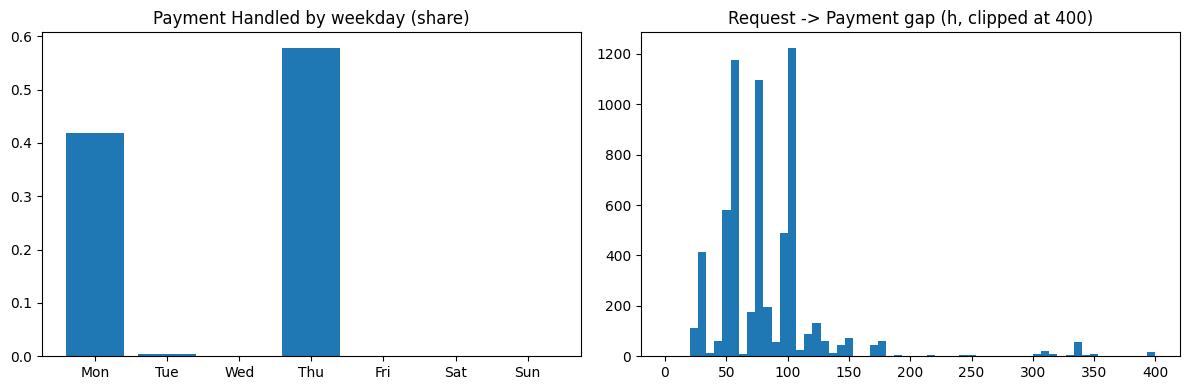

In [ ]:
# 2.4 Payment batch schedule — DERIVED from the data
pay_ev = events[events[ACTIVITY_COL] == ACT_PAYMENT].copy()
dow_share = (pay_ev[TIME_COL].dt.weekday.value_counts(normalize=True)
             .reindex(range(7), fill_value=0.0))
if BATCH_WEEKDAYS is None:
    BATCH_WEEKDAYS = sorted(int(d) for d in dow_share[dow_share >= 0.10].index)
batch_share = float(dow_share[BATCH_WEEKDAYS].sum()) if BATCH_WEEKDAYS else 0.0
BATCHED = bool(batch_share >= 0.90 and 0 < len(BATCH_WEEKDAYS) <= 3)
if BATCH_HOUR is None:
    on_batch = pay_ev[pay_ev[TIME_COL].dt.weekday.isin(BATCH_WEEKDAYS)]
    BATCH_HOUR = int(on_batch[TIME_COL].dt.hour.mode().iloc[0]) if len(on_batch) else 12
if MULTI_BATCH_HRS is None:
    if BATCHED and len(BATCH_WEEKDAYS) > 1:
        d = BATCH_WEEKDAYS + [BATCH_WEEKDAYS[0] + 7]
        MULTI_BATCH_HRS = 2 * 24 * max(np.diff(d))
    elif BATCHED:
        MULTI_BATCH_HRS = 2 * 24 * 7
    else:
        MULTI_BATCH_HRS = float(req_pay_gaps.quantile(0.95))
DAYNAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("Payment share by weekday:",
      {DAYNAMES[i]: round(float(v), 4) for i, v in dow_share.items()})
print(f"BATCH_WEEKDAYS={[DAYNAMES[d] for d in BATCH_WEEKDAYS]}  BATCH_HOUR={BATCH_HOUR}  "
      f"batch share={batch_share:.4f}  BATCHED={BATCHED}  MULTI_BATCH_HRS={MULTI_BATCH_HRS}")

def hours_to_next_batch_vec(ts):
    """Hours from each timestamp to the next scheduled batch slot (UTC).
    Returns zeros when the log has no batch schedule."""
    ts = pd.to_datetime(pd.Series(ts), utc=True)
    if not BATCHED:
        return pd.Series(0.0, index=ts.index)
    base = ts.dt.normalize() + pd.Timedelta(hours=BATCH_HOUR)
    best = pd.Series(pd.NaT, index=ts.index, dtype="datetime64[ns, UTC]")
    for add in range(8):
        cand = base + pd.Timedelta(days=add)
        ok = cand.dt.weekday.isin(BATCH_WEEKDAYS) & (cand > ts) & best.isna()
        best.loc[ok] = cand.loc[ok]
    return (best - ts).dt.total_seconds() / 3600

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(DAYNAMES, dow_share.values)
ax[0].set_title("Payment Handled by weekday (share)")
ax[1].hist(req_pay_gaps.clip(upper=400), bins=60)
ax[1].set_title("Request -> Payment gap (h, clipped at 400)")
save_fig("02_payment_batching")

derived = {"BATCH_WEEKDAYS": BATCH_WEEKDAYS, "BATCH_HOUR": BATCH_HOUR,
           "BATCHED": BATCHED, "batch_share": batch_share,
           "MULTI_BATCH_HRS": float(MULTI_BATCH_HRS),
           "median_req_to_pay_h": float(req_pay_gaps.median()) if len(req_pay_gaps) else None}
json.dump(derived, open(f"{RESULT_DIR}/02_derived_constants.json", "w"), indent=2)


In [ ]:
# 2.5 Prefix-length structure + bucket density (prefix space)
cases_reaching_k = events.groupby("event_idx")[CASE_COL].nunique()
prefix_table = pd.DataFrame({"k": cases_reaching_k.index,
                             "cases_reaching_k": cases_reaching_k.values})
prefix_table["share_%"] = (prefix_table["cases_reaching_k"] / phase1["cases"] * 100).round(1)
prefix_table.to_csv(f"{RESULT_DIR}/02_prefix_lengths.csv", index=False)
print(prefix_table.head(12).to_string(index=False))
bucket_density = events["event_idx"].map(bucket_of).value_counts().reindex(BUCKETS)
print("\nPrefixes per bucket:", bucket_density.to_dict())
for b, n in bucket_density.items():
    if n < MIN_PREFIXES_PER_BUCKET:
        print(f"WARNING: bucket {b} has {n} prefixes (< {MIN_PREFIXES_PER_BUCKET}); "
              f"consider changing BUCKET_EDGES.")


 k  cases_reaching_k  share_%
 1              6886    100.0
 2              6814     99.0
 3              6806     98.8
 4              6412     93.1
 5              5768     83.8
 6              2393     34.8
 7               589      8.6
 8               540      7.8
 9               307      4.5
10               134      1.9
11                71      1.0
12                31      0.5

Prefixes per bucket: {'1-3': 20506, '4-5': 12180, '6+': 4110}


In [ ]:
# 2.6 Case skeleton
grp = events.groupby(CASE_COL)
skel = grp.agg(start_time=(TIME_COL, "min"), end_time=(TIME_COL, "max"),
               length=("event_idx", "max"), amount=(AMOUNT_COL, "first"))
skel["duration_h"] = ((skel.end_time - skel.start_time).dt.total_seconds() / 3600).round(2)
skel["variant"] = variant
skel["n_request_payment"] = (events[ACTIVITY_COL] == ACT_REQUEST).groupby(events[CASE_COL]).sum()
skel["n_payment_handled"] = (events[ACTIVITY_COL] == ACT_PAYMENT).groupby(events[CASE_COL]).sum()
skel = skel.join(per_case)
skel["has_missing_role"] = (events[ROLE_COL] == "MISSING").groupby(events[CASE_COL]).any()
skel["reaches_payment"] = skel["n_payment_handled"] > 0
skel = skel.reset_index()
pass  # v7: v2 file not rewritten
print("Case skeleton:", skel.shape)


Case skeleton: (6886, 15)


In [ ]:
# 2.7 Payment structure: duplicates, bypasses, off-batch, never-paid, delays
max_pay = int(skel.n_payment_handled.max())
max_req = int(skel.n_request_payment.max())
pay_no_req = skel[(skel.n_payment_handled > 0) & (skel.n_request_payment == 0)]
req_no_pay = skel[(skel.n_request_payment > 0) & (skel.n_payment_handled == 0)]
if BATCHED:
    off_ids = set(pay_ev.loc[~pay_ev[TIME_COL].dt.weekday.isin(BATCH_WEEKDAYS), CASE_COL])
else:
    off_ids = set()
off_batch = skel[skel[CASE_COL].isin(off_ids)]
never_paid = skel[~skel.reaches_payment]
gap_case = (ev_seq[(ev_seq[ACTIVITY_COL] == ACT_REQUEST) & (ev_seq["next_act"] == ACT_PAYMENT)]
            .set_index(CASE_COL)["gap_h"])
delayed = skel[skel[CASE_COL].isin(gap_case[gap_case > MULTI_BATCH_HRS].index)]
heavy_rework = skel[skel.n_rework_loops >= HEAVY_REWORK_LOOPS]

print(f"Max Payment Handled per case: {max_pay} | max Request Payment per case: {max_req}")
print("Payment WITHOUT request (natural bypass):", len(pay_no_req))
print("Request WITHOUT payment                 :", len(req_no_pay))
print("Off-batch payment cases                 :", len(off_batch))
print(f"Never-paid cases: {len(never_paid)} "
      f"(rejected-terminal {int((never_paid.n_rejections > 0).sum())}, "
      f"abandoned {int((never_paid.n_rejections == 0).sum())})")
print(f"Multi-batch delayed (> {MULTI_BATCH_HRS} h)    :", len(delayed))
print(f"Heavy rework (>= {HEAVY_REWORK_LOOPS} loops)          :", len(heavy_rework))
for name, df_ in [("pay_without_request", pay_no_req), ("request_without_pay", req_no_pay),
                  ("off_batch_payments", off_batch), ("never_paid", never_paid),
                  ("multi_batch_delayed", delayed), ("heavy_rework", heavy_rework)]:
    df_.to_csv(f"{RESULT_DIR}/02_{name}.csv", index=False)


Max Payment Handled per case: 1 | max Request Payment per case: 1
Payment WITHOUT request (natural bypass): 5
Request WITHOUT payment                 : 1
Off-batch payment cases                 : 23
Never-paid cases: 579 (rejected-terminal 497, abandoned 82)
Multi-batch delayed (> 192 h)    : 153
Heavy rework (>= 2 loops)          : 66


In [ ]:
# 2.8 Cross-case rare-amount clusters (rarity filter + cluster chaining + payment time)
pay_time = pay_ev.groupby(CASE_COL)[TIME_COL].first().rename("pay_time")
amt2 = (skel.set_index(CASE_COL)[["amount"]].join(pay_time, how="inner")
        .reset_index().dropna())
amount_freq_all = skel["amount"].value_counts()
amt2["is_rare"] = amt2["amount"].map(amount_freq_all).le(RARE_AMOUNT_MAX)
amt2 = amt2.sort_values(["amount", "pay_time"])
amt2["gap_d"] = amt2.groupby("amount")["pay_time"].diff().dt.total_seconds() / 86400
amt2["cluster_id"] = (amt2["gap_d"].isna() | (amt2["gap_d"] > REPEAT_WINDOW_D)).cumsum()
clusters = amt2.groupby("cluster_id").agg(
    amount=("amount", "first"), n_cases=(CASE_COL, "nunique"), rare=("is_rare", "first"),
    first_pay=("pay_time", "min"), last_pay=("pay_time", "max"))
clusters["same_instant"] = clusters["first_pay"] == clusters["last_pay"]
rare_clusters = clusters[(clusters.n_cases >= 2) & clusters.rare]
member = amt2.merge(rare_clusters[[]], left_on="cluster_id", right_index=True)
RARE_CLUSTER_CASES = set(member[CASE_COL])
print("Multi-case clusters within window:", int((clusters.n_cases >= 2).sum()))
print("Rare-amount clusters:", len(rare_clusters), "| cases:", len(RARE_CLUSTER_CASES),
      "| same-instant:", int(rare_clusters.same_instant.sum()))
rare_clusters.to_csv(f"{RESULT_DIR}/02_rare_amount_clusters.csv")
pd.Series(sorted(RARE_CLUSTER_CASES), name=CASE_COL).to_csv(
    f"{RESULT_DIR}/02_rare_cluster_cases.csv", index=False)


Multi-case clusters within window: 49
Rare-amount clusters: 37 | cases: 76 | same-instant: 30


In [ ]:
# 2.9 Track-B PRE-REGISTRATION (frozen before any model exists)
TRACKB = {
    "C1_payment_without_request": set(pay_no_req[CASE_COL]),
    "C2_off_batch_payment": set(off_batch[CASE_COL]),
    "C3_rare_amount_cluster": RARE_CLUSTER_CASES,
    "C4_multi_batch_delay": set(delayed[CASE_COL]),
    "C5_heavy_rework": set(heavy_rework[CASE_COL]),
}
def _write_prereg(path):
    lines = [f"# Track-B pre-registration — {LOG_NAME}",
             f"Frozen: {datetime.datetime.now().isoformat(timespec='seconds')}",
             "Written BEFORE any detector was trained. Criteria and thresholds:",
             f"- C1 payment without request (n={len(TRACKB['C1_payment_without_request'])})",
             f"- C2 payment outside batch weekdays {[DAYNAMES[d] for d in BATCH_WEEKDAYS]} "
             f"(n={len(TRACKB['C2_off_batch_payment'])})",
             f"- C3 rare amount (in <= {RARE_AMOUNT_MAX} cases) repeated across cases paid "
             f"within {REPEAT_WINDOW_D} days (n={len(RARE_CLUSTER_CASES)})",
             f"- C4 request->payment gap > {MULTI_BATCH_HRS} h (n={len(TRACKB['C4_multi_batch_delay'])})",
             f"- C5 >= {HEAVY_REWORK_LOOPS} rework loops (n={len(TRACKB['C5_heavy_rework'])})",
             "Verdict rule: 'domain-supported suspicious' = >= 2 independent indicators "
             "from different perspectives; 1 indicator = weak support.",
             "Overlap disclosure: C1, C2, C3, C4 and C5 also exist as F-rules (F6, F7, F3, F8, F9); "
             "plausibility is reported with and without overlap cases."]
    open(path, "w").write("\n".join(lines))
write_frozen(f"{FROZEN_DIR}/trackB_preregistration.md", _write_prereg)
print(open(f"{FROZEN_DIR}/trackB_preregistration.md").read())

audit = {"max_pay_per_case": max_pay, "pay_without_request": len(pay_no_req),
         "request_without_pay": len(req_no_pay), "off_batch_cases": len(off_batch),
         "never_paid": len(never_paid), "rare_clusters": len(rare_clusters),
         "rare_cluster_cases": len(RARE_CLUSTER_CASES), "delayed": len(delayed),
         "heavy_rework": len(heavy_rework), "variants": len(variant_counts), **derived}
pd.DataFrame([audit]).to_csv(f"{RESULT_DIR}/02_audit_summary.csv", index=False)


FROZEN (kept existing): trackB_preregistration.md
# Track-B pre-registration — BPIC20_R
Frozen: 2026-10-06T14:06:06
Written BEFORE any detector was trained. Criteria and thresholds:
- C1 payment without request (n=5)
- C2 payment outside batch weekdays [] (n=0)
- C3 rare amount (in <= 3 cases) repeated across cases paid within 7 days (n=76)
- C4 request->payment gap > 149.11401388888888 h (n=315)
- C5 >= 2 rework loops (n=66)
Verdict rule: 'domain-supported suspicious' = >= 2 independent indicators from different perspectives; 1 indicator = weak support.
Overlap disclosure: C1, C2, C3, C4 and C5 also exist as F-rules (F6, F7, F3, F8, F9); plausibility is reported with and without overlap cases.


In [ ]:
# 3.1 Train / val / test split by case (FROZEN)
from sklearn.model_selection import train_test_split
SPLIT_PATH = f"{FROZEN_DIR}/case_split.csv"
def _write_split(path):
    ids, strat = skel[CASE_COL], skel["reaches_payment"]
    tr, tmp = train_test_split(ids, test_size=1 - SPLIT[0],
                               random_state=RANDOM_SEED, stratify=strat)
    va, te = train_test_split(tmp, test_size=SPLIT[2] / (SPLIT[1] + SPLIT[2]),
                              random_state=RANDOM_SEED, stratify=strat.loc[tmp.index])
    out = pd.DataFrame({CASE_COL: ids, "split": "train"})
    out.loc[out[CASE_COL].isin(va), "split"] = "val"
    out.loc[out[CASE_COL].isin(te), "split"] = "test"
    out.to_csv(path, index=False)
write_frozen(SPLIT_PATH, _write_split)
split_map = pd.read_csv(SPLIT_PATH, dtype={CASE_COL: str}).set_index(CASE_COL)["split"]
events["split"] = events[CASE_COL].map(split_map)
skel["split"] = skel[CASE_COL].map(split_map)
assert events["split"].notna().all(), "cases missing from the frozen split"
print(skel["split"].value_counts().to_dict())
print("reaches_payment share:", skel.groupby("split")["reaches_payment"].mean().round(4).to_dict())


FROZEN (kept existing): case_split.csv
{'train': 4131, 'test': 1378, 'val': 1377}
reaches_payment share: {'test': 0.9158, 'train': 0.916, 'val': 0.9158}


In [ ]:
# 3.2 Feature builder — ONE function for the natural and the injected world.
# SET B (behavioural) + SET S (state): no money. SET F: money, consequence lane only.
def build_features(ev):
    ev = ev.sort_values([CASE_COL, "event_idx"]).reset_index(drop=True).copy()
    ev[TIME_COL] = pd.to_datetime(ev[TIME_COL], utc=True)
    ev["prefix_key"] = (ev.groupby(CASE_COL)[ACTIVITY_COL]
                        .transform(lambda s: (s + "|").cumsum().str[:-1]))
    ev["prev_act"] = ev.groupby(CASE_COL)[ACTIVITY_COL].shift(1)
    tr = ev["split"] == "train"                     # train-only statistic maps
    pf_map = ev.loc[tr, "prefix_key"].value_counts()
    tf_map = ev[tr & ev["prev_act"].notna()].groupby(["prev_act", ACTIVITY_COL]).size()
    rare_cut = tf_map.sum() * 0.001
    tr_amt = ev[tr].groupby(CASE_COL)[AMOUNT_COL].first().dropna()
    amt_freq, amt_sorted = tr_amt.value_counts(), np.sort(tr_amt.values)

    p = ev[[CASE_COL, ACTIVITY_COL, TIME_COL, ROLE_COL, "event_idx", "split",
            "prefix_key", "prev_act"]].copy()
    g = p.groupby(CASE_COL)
    p["B_len"] = p["event_idx"]
    p["B_n_unique_acts"] = g[ACTIVITY_COL].transform(lambda s: (~s.duplicated()).cumsum())
    p["B_unique_ratio"] = p["B_n_unique_acts"] / p["B_len"]
    p["B_repeat_ratio"] = 1 - p["B_unique_ratio"]
    p["_s"] = p[ACTIVITY_COL].str.contains(SUBMIT_TOKEN, regex=False).astype(int)
    p["_r"] = p[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False).astype(int)
    p["_a"] = p[ACTIVITY_COL].str.contains(APPROVE_TOKEN, regex=False).astype(int)
    p["_rs_"] = ((p["_s"] == 1) & (p.groupby([CASE_COL, ACTIVITY_COL]).cumcount() >= 1)).astype(int)
    p["B_n_submissions_so_far"] = g["_s"].cumsum()
    p["B_n_rejections_so_far"] = g["_r"].cumsum()
    p["B_n_approvals_so_far"] = g["_a"].cumsum()
    p["B_rework_loops_so_far"] = p.groupby(CASE_COL)["_rs_"].cumsum()
    pf = p["prefix_key"].map(pf_map).fillna(0.0)
    p["B_prefix_log_freq"] = np.log1p(pf)
    p["B_prefix_is_unseen"] = (pf == 0).astype(int)
    tf_ = pd.Series(tf_map.reindex(pd.MultiIndex.from_frame(p[["prev_act", ACTIVITY_COL]])).values,
                    index=p.index).fillna(0.0)
    p["_rt"] = ((tf_ < rare_cut) & p["prev_act"].notna()).astype(int)
    p["B_rare_trans_so_far"] = g["_rt"].cumsum()
    p["_rc"] = p[ROLE_COL].replace({"MISSING": "UNKNOWN_ROLE"})
    p["_rs"] = ((p["_rc"] != g["_rc"].shift(1)) & g["_rc"].shift(1).notna()).astype(int)
    p["B_role_switches_so_far"] = g["_rs"].cumsum()
    p["_mr"] = (p[ROLE_COL] == "MISSING").astype(int)
    p["B_missing_role_so_far"] = g["_mr"].cumsum().clip(upper=1)
    p["_gap"] = (p[TIME_COL] - g[TIME_COL].shift(1)).dt.total_seconds() / 3600
    p["B_dur_so_far_h"] = (p[TIME_COL] - g[TIME_COL].transform("first")).dt.total_seconds() / 3600
    p["B_mean_gap_h"] = p["B_dur_so_far_h"] / (p["B_len"] - 1).clip(lower=1)
    p["B_max_gap_h"] = p.groupby(CASE_COL)["_gap"].cummax().fillna(0.0)
    p["B_last_gap_h"] = p["_gap"].fillna(0.0)
    p["_we"] = (p[TIME_COL].dt.weekday >= 5).astype(int)
    p["_oh"] = (~p[TIME_COL].dt.hour.between(8, 18)).astype(int)
    p["B_weekend_ratio_so_far"] = g["_we"].cumsum() / p["B_len"]
    p["B_offhours_ratio_so_far"] = g["_oh"].cumsum() / p["B_len"]
    p["_ir"] = (p[ACTIVITY_COL] == ACT_REQUEST).astype(int)
    p["_ip"] = (p[ACTIVITY_COL] == ACT_PAYMENT).astype(int)
    p["S_n_requests_so_far"] = g["_ir"].cumsum()
    p["S_n_payments_so_far"] = g["_ip"].cumsum()
    p["S_request_seen"] = (p["S_n_requests_so_far"] > 0).astype(int)
    p["S_payment_seen"] = (p["S_n_payments_so_far"] > 0).astype(int)
    p["_rtf"] = p[TIME_COL].where(p["_ir"] == 1).groupby(p[CASE_COL]).ffill()
    p["S_hours_since_request"] = ((p[TIME_COL] - p["_rtf"]).dt.total_seconds() / 3600
                                  ).fillna(0.0).clip(lower=0)
    p["_bw"] = np.nan
    m = p["_ir"] == 1
    if m.any():
        p.loc[m, "_bw"] = hours_to_next_batch_vec(p.loc[m, TIME_COL]).values
    p["_bw"] = p.groupby(CASE_COL)["_bw"].ffill()
    p["B_excess_wait_h"] = (p["S_hours_since_request"] - p["_bw"]).clip(lower=0).fillna(0.0)
    p["B_multi_batch_delay"] = (p["S_hours_since_request"] > MULTI_BATCH_HRS).astype(int)
    p["S_hours_to_next_batch"] = hours_to_next_batch_vec(p[TIME_COL]).values
    # ---- SET F (consequence lane only) ----
    amt_map = ev.groupby(CASE_COL)[AMOUNT_COL].first()
    p["F_amount"] = p[CASE_COL].map(amt_map)
    p["F_log_amount"] = np.log1p(p["F_amount"].clip(lower=0))
    p["F_amount_train_freq"] = p["F_amount"].map(amt_freq).fillna(0)
    p["F_is_rare_amount"] = (p["F_amount_train_freq"] <= RARE_AMOUNT_MAX).astype(int)
    p["F_amount_pctile"] = (np.searchsorted(amt_sorted, p["F_amount"].fillna(0).values)
                            / max(len(amt_sorted), 1))
    p["F_potential_exposure"] = np.where((p["S_request_seen"] == 1) & (p["S_payment_seen"] == 0),
                                         p["F_amount"].fillna(0), 0.0)
    p["F_settled_amount"] = np.where(p["S_payment_seen"] == 1, p["F_amount"].fillna(0), 0.0)
    p["bucket"] = p["event_idx"].map(bucket_of)
    return p.drop(columns=[c for c in p.columns if c.startswith("_")] + ["prefix_key", "prev_act"])

PX_PATH = f"{FEATURE_DIR}/prefix_features.parquet"
if cached(PX_PATH):
    px = pd.read_parquet(PX_PATH)
    px[TIME_COL] = pd.to_datetime(px[TIME_COL], utc=True)
    print("Loaded cached prefix features:", px.shape)
else:
    px = build_features(events)
    px.to_parquet(PX_PATH, index=False)
    print("Built prefix features:", px.shape)

B_COLS = [c for c in px.columns if c.startswith("B_")]
S_COLS = [c for c in px.columns if c.startswith("S_")]
F_COLS = [c for c in px.columns if c.startswith("F_")]
DETECTOR_FEATURES = B_COLS + S_COLS
leaky = [c for c in DETECTOR_FEATURES if "amount" in c.lower() or c.startswith("F_")]
assert not leaky, f"SEAL VIOLATION: {leaky}"
assert len(px) == len(events), "one row per event (= per prefix) expected"
assert px[DETECTOR_FEATURES + F_COLS].isna().sum().sum() == 0, "NaNs in features"
pd.DataFrame({"feature": B_COLS + S_COLS + F_COLS,
              "set": ["B"] * len(B_COLS) + ["S"] * len(S_COLS) + ["F"] * len(F_COLS),
              "detector_input": [True] * len(DETECTOR_FEATURES) + [False] * len(F_COLS)}
             )  # v7: v2 file not rewritten
print(f"Detector features: {len(DETECTOR_FEATURES)} | financial features: {len(F_COLS)} | seal OK")
print("Unseen-prefix share by split:", px.groupby("split")["B_prefix_is_unseen"].mean().round(4).to_dict())


Loaded cached prefix features: (36796, 41)
Detector features: 27 | financial features: 7 | seal OK
Unseen-prefix share by split: {'test': 0.006, 'train': 0.0, 'val': 0.0046}


In [ ]:
# 4.1 TensorFlow setup
import joblib
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
tf.keras.utils.set_random_seed(RANDOM_SEED)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
train_mask = (px["split"] == "train").values


TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# 4.2 BASELINE 1 — Isolation Forest on tabular B+S features
IF_PATH, SCALER_PATH = f"{MODEL_DIR}/if.joblib", f"{MODEL_DIR}/scaler.joblib"
if cached(IF_PATH) and cached(SCALER_PATH):
    if_model, scaler = joblib.load(IF_PATH), joblib.load(SCALER_PATH)
    print("Loaded Isolation Forest.")
else:
    scaler = StandardScaler().fit(px.loc[train_mask, DETECTOR_FEATURES])
    if_model = IsolationForest(n_estimators=200, max_samples=256, random_state=RANDOM_SEED,
                               n_jobs=-1).fit(scaler.transform(px.loc[train_mask, DETECTOR_FEATURES]))
    joblib.dump(if_model, IF_PATH); joblib.dump(scaler, SCALER_PATH)
    print("Trained Isolation Forest.")

def score_if(p):
    return -if_model.score_samples(scaler.transform(p[DETECTOR_FEATURES]))


Loaded Isolation Forest.


In [ ]:
# 4.3 BASELINE 2 — LSTM autoencoder on activity sequences (v1 design, mean error)
AE_PATH, AE_META = f"{MODEL_DIR}/ae.keras", f"{MODEL_DIR}/ae_meta.joblib"
if cached(AE_META):
    ae_meta = joblib.load(AE_META)
else:
    acts = sorted(events.loc[events.split == "train", ACTIVITY_COL].unique())
    ae_meta = {"act2id": {a: i + 1 for i, a in enumerate(acts)}}
    ae_meta["UNK"] = len(acts) + 1
    ae_meta["VOCAB"] = len(acts) + 2
    joblib.dump(ae_meta, AE_META)
ACT2ID, AE_UNK, AE_VOCAB = ae_meta["act2id"], ae_meta["UNK"], ae_meta["VOCAB"]

def prefix_seq_matrix(ev, p):
    seqs = (ev.sort_values([CASE_COL, "event_idx"]).groupby(CASE_COL)[ACTIVITY_COL]
            .agg(lambda s: [ACT2ID.get(a, AE_UNK) for a in s]).to_dict())
    M = np.zeros((len(p), AE_MAXLEN), dtype=np.int32)
    for i, (cid, k) in enumerate(zip(p[CASE_COL].values, p["event_idx"].values)):
        ids = seqs[cid][:min(int(k), AE_MAXLEN)]
        M[i, :len(ids)] = ids
    return M

def build_ae():
    inp = layers.Input(shape=(AE_MAXLEN,), dtype="int32")
    h = layers.Embedding(AE_VOCAB, 16, mask_zero=True)(inp)
    h = layers.LSTM(64)(h)
    h = layers.RepeatVector(AE_MAXLEN)(h)
    h = layers.LSTM(64, return_sequences=True)(h)
    out = layers.TimeDistributed(layers.Dense(AE_VOCAB, activation="softmax"))(h)
    m = Model(inp, out)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
    return m

def score_ae(model, M, batch=4096):
    errs = np.zeros(len(M))
    for s in range(0, len(M), batch):
        xb = M[s:s + batch]
        probs = model.predict(xb, verbose=0)
        pt = np.take_along_axis(probs, xb[..., None], axis=2)[..., 0]
        ce = -np.log(np.clip(pt, 1e-9, 1.0))
        mk = xb > 0
        errs[s:s + batch] = (ce * mk).sum(1) / np.maximum(mk.sum(1), 1)
    return errs

SEQ_NAT = prefix_seq_matrix(events, px)
if cached(AE_PATH):
    ae = tf.keras.models.load_model(AE_PATH, compile=False)
    print("Loaded autoencoder.")
else:
    tf.keras.utils.set_random_seed(RANDOM_SEED)
    ae = build_ae()
    ae.fit(SEQ_NAT[train_mask], SEQ_NAT[train_mask], validation_split=0.1,
           epochs=AE_EPOCHS, batch_size=256, verbose=2,
           callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
    ae.save(AE_PATH)


Loaded autoencoder.


In [ ]:
# 4.4 IMPROVED — multi-perspective next-event model
# Event score = -log P(activity, role, time-gap bucket | earlier events); prefix
# score = max over its events (worst event, not diluted). Causal => one pass
# scores every prefix, so it is streaming-native. No amount enters the model.
GAP_EDGES_H = [1 / 60, 1, 24, 72, 168]
PAD, BOS, UNK, EOS = 0, 1, 2, 3     # EOS teaches the model where a case ends
NE_VARIANTS = {"act": ["act"], "act_role": ["act", "role"], "full": ["act", "role", "gap"]}
NE_SCORE_COLS = [f"{agg}_{v}" for agg in ["max", "mean"] for v in NE_VARIANTS]

def add_tokens(ev):
    ev = ev.sort_values([CASE_COL, "event_idx"]).copy()
    gap_h = ev.groupby(CASE_COL)[TIME_COL].diff().dt.total_seconds() / 3600
    b = np.digitize(gap_h.fillna(0).values, GAP_EDGES_H) + 1
    ev["gap_tok"] = np.where(gap_h.isna().values, 0, b).astype(str)
    ev["role_tok"] = ev[ROLE_COL].fillna("NA").astype(str).replace({"MISSING": "UNKNOWN_ROLE"})
    return ev

NE_COLS = {"act": ACTIVITY_COL, "role": "role_tok", "gap": "gap_tok"}
PERSP = list(NE_COLS)
NE_META = f"{MODEL_DIR}/ne_meta.joblib"
ev_tok = add_tokens(events)
if cached(NE_META):
    VOC = joblib.load(NE_META)["VOC"]
else:
    trm = ev_tok["split"] == "train"
    VOC = {p: {v: i + 4 for i, v in enumerate(sorted(ev_tok.loc[trm, c].unique()))}
           for p, c in NE_COLS.items()}
    joblib.dump({"VOC": VOC, "GAP_EDGES_H": GAP_EDGES_H, "NE_MAXLEN": NE_MAXLEN}, NE_META)
VSIZE = {p: len(v) + 4 for p, v in VOC.items()}
print("Next-event vocab sizes:", VSIZE)

def encode_cases(ev):
    ev = ev.sort_values([CASE_COL, "event_idx"]).copy()
    for p in PERSP:
        ev[f"_{p}"] = ev[NE_COLS[p]].map(VOC[p]).fillna(UNK).astype(np.int32)
    groups = list(ev.groupby(CASE_COL, sort=True))
    n = len(groups)
    Y = {p: np.zeros((n, NE_MAXLEN), np.int32) for p in PERSP}
    lens, ids = np.zeros(n, np.int32), []
    for i, (cid, gdf) in enumerate(groups):
        ids.append(cid)
        lens[i] = len(gdf)
        L = min(len(gdf), NE_MAXLEN - 1)          # leave room for EOS
        for p in PERSP:
            Y[p][i, :L] = gdf[f"_{p}"].values[:L]
            if len(gdf) <= NE_MAXLEN - 1:
                Y[p][i, L] = EOS                   # target after the last event
    X = {p: np.concatenate([np.full((n, 1), BOS, np.int32), Y[p][:, :-1]], 1) for p in PERSP}
    return np.array(ids), X, Y, lens

def masked_sce(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    ce = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    m = tf.cast(y_true > 0, ce.dtype)
    return tf.reduce_sum(ce * m) / tf.maximum(tf.reduce_sum(m), 1.0)

def build_ne(hidden=128, drop=0.1):
    dims = {"act": 32, "role": 8, "gap": 8}
    ins = [layers.Input((NE_MAXLEN,), dtype="int32", name=f"in_{p}") for p in PERSP]
    embs = [layers.Embedding(VSIZE[p], dims[p])(i) for p, i in zip(PERSP, ins)]
    h = layers.Dropout(drop)(layers.Concatenate()(embs))
    h = layers.LSTM(hidden, return_sequences=True)(h)
    h = layers.Dropout(drop)(h)
    h = layers.LSTM(hidden, return_sequences=True)(h)
    outs = [layers.Dense(VSIZE[p], activation="softmax", name=f"out_{p}")(h) for p in PERSP]
    m = Model(ins, outs)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=[masked_sce] * len(PERSP))
    return m

def train_ne(ev_tokens_train, seed, verbose=2):
    tf.keras.utils.set_random_seed(seed)
    _, X, Y, _ = encode_cases(ev_tokens_train)
    idx = np.random.default_rng(seed).permutation(len(Y["act"]))
    cut = int(0.9 * len(idx))
    a, b = idx[:cut], idx[cut:]
    m = build_ne()
    m.fit([X[p][a] for p in PERSP], [Y[p][a] for p in PERSP],
          validation_data=([X[p][b] for p in PERSP], [Y[p][b] for p in PERSP]),
          epochs=NE_EPOCHS, batch_size=128, verbose=verbose,
          callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    return m

def ne_event_scores(model, ev_tokens):
    """Per-event NLL per perspective + prefix scores (max/mean x variants)."""
    cids, X, Y, lens = encode_cases(ev_tokens)
    probs = model.predict([X[p] for p in PERSP], batch_size=512, verbose=0)
    mask = np.arange(NE_MAXLEN)[None, :] < np.minimum(lens, NE_MAXLEN - 1)[:, None]  # real events only
    ci, ti = np.nonzero(mask)
    d = pd.DataFrame({CASE_COL: cids[ci], "event_idx": ti + 1})
    for p, pr in zip(PERSP, probs):
        pt = np.take_along_axis(pr, Y[p][..., None], axis=2)[..., 0]
        d[f"nll_{p}"] = -np.log(np.clip(pt[ci, ti], 1e-9, 1.0))
    for v, parts in NE_VARIANTS.items():
        e = d[[f"nll_{p}" for p in parts]].sum(axis=1)
        d[f"e_{v}"] = e
        d[f"max_{v}"] = e.groupby(d[CASE_COL]).cummax()
        d[f"mean_{v}"] = e.groupby(d[CASE_COL]).cumsum() / d["event_idx"]
    return d

NE_PATH = f"{MODEL_DIR}/next_event.keras"
if cached(NE_PATH):
    ne_model = tf.keras.models.load_model(NE_PATH, compile=False)
    print("Loaded next-event model.")
else:
    ne_model = train_ne(ev_tok[ev_tok.split == "train"], RANDOM_SEED)
    ne_model.save(NE_PATH)


Next-event vocab sizes: {'act': 21, 'role': 12, 'gap': 11}
Loaded next-event model.


In [ ]:
# 4.5 Score the natural log with every detector; per-bucket calibration on TRAIN
RAW_TO_A = {"raw_IF": "A_IF", "raw_AE": "A_AE",
            **{c: f"A_NE_{c}" for c in NE_SCORE_COLS}}

def score_detectors(ev, p, model=None, seq=None):
    """Adds raw detector scores to prefix table p (rows aligned by case, event_idx)."""
    model = model or ne_model
    out = p.copy()
    out["raw_IF"] = score_if(out)
    out["raw_AE"] = score_ae(ae, seq if seq is not None else prefix_seq_matrix(ev, out))
    ne = ne_event_scores(model, add_tokens(ev))
    out = out.merge(ne[[CASE_COL, "event_idx"] + NE_SCORE_COLS],
                    on=[CASE_COL, "event_idx"], how="left")
    out[NE_SCORE_COLS] = out.groupby(CASE_COL)[NE_SCORE_COLS].ffill()   # beyond NE_MAXLEN
    return out, ne

def fit_refs(p, mask):
    return {f"{c}|{b}": np.sort(p.loc[mask & (p["bucket"] == b).values, c].values)
            for c in RAW_TO_A for b in BUCKETS}

def apply_refs(p, refs):
    for raw, a in RAW_TO_A.items():
        out = np.zeros(len(p))
        for b in BUCKETS:
            m = (p["bucket"] == b).values
            out[m] = midpoint_rank(p.loc[m, raw].values, refs[f"{raw}|{b}"])
        p[a] = out
    p["A_ENS"] = (p["A_IF"] + p["A_AE"]) / 2           # v1 anomaly lane
    return p

NAT_SCORES = f"{FEATURE_DIR}/natural_scores.parquet"
NAT_NE_EV = f"{FEATURE_DIR}/natural_ne_events.parquet"
REFS_PATH = f"{MODEL_DIR}/calibration_refs.joblib"
if cached(NAT_SCORES) and cached(NAT_NE_EV) and cached(REFS_PATH):
    px = pd.read_parquet(NAT_SCORES)
    px[TIME_COL] = pd.to_datetime(px[TIME_COL], utc=True)
    ne_nat = pd.read_parquet(NAT_NE_EV)
    REFS = joblib.load(REFS_PATH)
    print("Loaded cached natural scores.")
else:
    px, ne_nat = score_detectors(events, px, seq=SEQ_NAT)
    REFS = fit_refs(px, train_mask)
    px = apply_refs(px, REFS)
    joblib.dump(REFS, REFS_PATH)
    ne_nat.to_parquet(NAT_NE_EV, index=False)
    px.to_parquet(NAT_SCORES, index=False)
A_NE_COLS = [f"A_NE_{c}" for c in NE_SCORE_COLS]
A_ALL = ["A_IF", "A_AE", "A_ENS"] + A_NE_COLS
print("Calibrated means by split (train = 0.50 by construction):")
print(px.groupby("split")[A_ALL].mean().round(3).T.to_string())
print("\nCorrelations: IF~AE %.3f | AE~NE(max_full) %.3f" % (
    px["A_IF"].corr(px["A_AE"]), px["A_AE"].corr(px["A_NE_max_full"])))


Loaded cached natural scores.
Calibrated means by split (train = 0.50 by construction):
split                test  train    val
A_IF                0.507    0.5  0.507
A_AE                0.501    0.5  0.502
A_ENS               0.504    0.5  0.505
A_NE_max_act        0.502    0.5  0.504
A_NE_max_act_role   0.502    0.5  0.504
A_NE_max_full       0.508    0.5  0.501
A_NE_mean_act       0.503    0.5  0.505
A_NE_mean_act_role  0.503    0.5  0.505
A_NE_mean_full      0.510    0.5  0.504

Correlations: IF~AE 0.594 | AE~NE(max_full) 0.647


In [ ]:
# 5.1 Rule registry v1 (FROZEN before fusion tuning and Track-B review)
REG_PATH = f"{FROZEN_DIR}/rule_registry_v1.json"
def _write_registry(path):
    reg = {"version": "1.0", "log": LOG_NAME,
           "frozen": datetime.datetime.now().isoformat(timespec="seconds"),
           "thresholds": {"batched": BATCHED, "batch_weekdays": BATCH_WEEKDAYS,
                          "batch_hour": BATCH_HOUR, "multi_batch_hrs": float(MULTI_BATCH_HRS),
                          "repeat_window_d": REPEAT_WINDOW_D, "rare_amount_max": RARE_AMOUNT_MAX,
                          "heavy_rework_loops": HEAVY_REWORK_LOOPS},
           "rules": {
               "F1": {"name": "Duplicate payment in case", "consequence": "loss", "severity": 3,
                      "survey_type": "rework", "source": "audit practice"},
               "F2": {"name": "Repeated payment request", "consequence": "exposure", "severity": 3,
                      "survey_type": "insert", "source": "audit practice"},
               "F3": {"name": "Rare amount in cross-case payment cluster", "consequence": "exposure",
                      "severity": 2, "survey_type": "attribute", "source": "audit + data"},
               "F6": {"name": "Payment without request (bypass)", "consequence": "exposure",
                      "severity": 3, "survey_type": "skip", "source": "audit practice"},
               "F7": {"name": "Off-batch payment", "consequence": "exposure", "severity": 2,
                      "survey_type": "attribute", "source": "data-derived"},
               "F8": {"name": "Multi-batch payment delay", "consequence": "exposure", "severity": 1,
                      "survey_type": "late", "source": "data-derived"},
               "F9": {"name": "Heavy rework reaching payment", "consequence": "exposure",
                      "severity": 1, "survey_type": "rework", "source": "data-derived"},
               "F10": {"name": "New request after an existing payment", "consequence": "exposure",
                       "severity": 3, "survey_type": "insert", "source": "audit practice"}},
           "omitted": {"F4": "within-case amount repeat impossible (one amount per case); folded into F3",
                       "F5": "amount inflation: no adjusted-amount field; Track A only (A3 not injected)"}}
    json.dump(reg, open(path, "w"), indent=2)
write_frozen(REG_PATH, _write_registry)
REG = json.load(open(REG_PATH))
RULES = list(REG["rules"])
print("Registry frozen on", REG["frozen"], "| rules:", RULES)


FROZEN (kept existing): rule_registry_v1.json
Registry frozen on 2026-10-06T14:11:14 | rules: ['F1', 'F2', 'F3', 'F6', 'F7', 'F8', 'F9', 'F10']


In [ ]:
# 5.2 Rule engine (prefix-computable) + F calibration on natural TRAIN prefixes
def apply_rules(p):
    th = REG["thresholds"]
    is_req = p[ACTIVITY_COL] == ACT_REQUEST
    is_pay = p[ACTIVITY_COL] == ACT_PAYMENT
    h = pd.DataFrame(index=p.index)
    h["F1"] = p["S_n_payments_so_far"] >= 2
    h["F2"] = p["S_n_requests_so_far"] >= 2
    h["F3"] = p[CASE_COL].isin(RARE_CLUSTER_CASES) & (p["S_payment_seen"] == 1)
    h["F6"] = (p["S_payment_seen"] == 1) & (p["S_n_requests_so_far"] == 0)
    if th["batched"]:
        offb = (is_pay & ~p[TIME_COL].dt.weekday.isin(th["batch_weekdays"])).astype(int)
        h["F7"] = offb.groupby(p[CASE_COL]).cummax() > 0
    else:
        h["F7"] = False
    h["F8"] = p["S_hours_since_request"] > th["multi_batch_hrs"]
    h["F9"] = (p["B_rework_loops_so_far"] >= th["heavy_rework_loops"]) & (p["S_payment_seen"] == 1)
    rap = (is_req & (p["S_n_payments_so_far"] >= 1)).astype(int)
    h["F10"] = rap.groupby(p[CASE_COL]).cummax() > 0
    h = h[RULES].astype(int)
    sev = sum(h[r] * REG["rules"][r]["severity"] for r in RULES)
    loss_rules = [r for r in RULES if REG["rules"][r]["consequence"] == "loss"]
    amt = p["F_amount"].fillna(0).clip(lower=0).values
    actual = np.where(h[loss_rules].sum(axis=1).values > 0, amt, 0.0)
    expo = np.where((sev.values > 0) & (actual == 0), amt, 0.0)
    out = p.copy()
    for r in RULES:
        out[f"hit_{r}"] = h[r].values
    out["severity_sum"] = sev.values
    out["n_rules_fired"] = h.sum(axis=1).values
    out["actual_loss"], out["potential_exposure"] = actual, expo
    out["money_at_risk"] = actual + expo
    out["F_raw"] = np.log1p(out["money_at_risk"]) * out["severity_sum"]
    return out

def apply_F(p):
    p["F"] = 0.0
    pos = p["F_raw"] > 0
    p.loc[pos, "F"] = midpoint_rank(p.loc[pos, "F_raw"].values, F_REF)
    return p

px = apply_rules(px)
F_REF = np.sort(px.loc[train_mask & (px["F_raw"] > 0).values, "F_raw"].values)
pass  # v7: v2 file not rewritten
px = apply_F(px)
print("Natural rule firings (prefixes):", {r: int(px[f"hit_{r}"].sum()) for r in RULES})
print("Prefixes with >=1 rule:", int((px.n_rules_fired > 0).sum()),
      "| F train-ref size:", len(F_REF))
pass  # v7: v2 file not rewritten


Natural rule firings (prefixes): {'F1': 0, 'F2': 0, 'F3': 76, 'F6': 7, 'F7': 0, 'F8': 315, 'F9': 63, 'F10': 2}
Prefixes with >=1 rule: 451 | F train-ref size: 259


In [ ]:
# 6.1 Injection engine — dtype-safe, batch-conformant, deterministic
REQ_PAY_POOL = req_pay_gaps.values if len(req_pay_gaps) else np.array([72.0])
APPROVALS = [a for a in events[ACTIVITY_COL].unique() if APPROVE_TOKEN in a]

def _next_slot(after_ts, rng):
    if BATCHED:
        base = after_ts.normalize()
        for add in range(9):
            cand = base + pd.Timedelta(days=add, hours=BATCH_HOUR,
                                       minutes=int(rng.integers(0, 60)))
            if cand.weekday() in BATCH_WEEKDAYS and cand > after_ts:
                return cand
    return after_ts + pd.Timedelta(hours=float(rng.choice(REQ_PAY_POOL)))

def _inject_case(cdf, itype, rng):
    cdf = cdf.sort_values("event_idx").reset_index(drop=True)
    cdf["_inj"] = 0
    amt = float(cdf[AMOUNT_COL].iloc[0])
    pay_i = cdf.index[cdf[ACTIVITY_COL] == ACT_PAYMENT]
    req_i = cdf.index[cdf[ACTIVITY_COL] == ACT_REQUEST]
    gt = {"type": itype, "amount": amt, "loss": 0.0, "exposure": 0.0}
    if itype == "A1":                                    # duplicate payment
        new = cdf.loc[[pay_i[-1]]].copy()
        new[TIME_COL] = _next_slot(cdf.loc[pay_i[-1], TIME_COL], rng)
        new["_inj"] = 1
        cdf = pd.concat([cdf, new], ignore_index=True)
        gt["loss"] = amt
    elif itype in ("A2", "A4"):                          # duplicate request (+ payment)
        new_r = cdf.loc[[req_i[-1]]].copy()
        new_r[TIME_COL] = cdf.loc[pay_i[-1], TIME_COL] + pd.Timedelta(hours=float(rng.uniform(24, 120)))
        new_r["_inj"] = 1
        parts = [cdf, new_r]
        if itype == "A4":
            new_p = cdf.loc[[pay_i[-1]]].copy()
            new_p[TIME_COL] = _next_slot(new_r[TIME_COL].iloc[0], rng)
            new_p["_inj"] = 2
            parts.append(new_p)
            gt["loss"] = amt
        else:
            gt["exposure"] = amt
        cdf = pd.concat(parts, ignore_index=True)
    elif itype == "A5":                                  # approval bypass (skip)
        cdf = cdf[~cdf[ACTIVITY_COL].isin(APPROVALS)].reset_index(drop=True)
        gt["exposure"] = amt
    cdf = cdf.sort_values(TIME_COL, kind="stable").reset_index(drop=True)
    cdf["event_idx"] = np.arange(1, len(cdf) + 1)
    if itype == "A1":
        a = l = int(cdf.index[cdf["_inj"] == 1][0])
    elif itype == "A2":
        a, l = int(cdf.index[cdf["_inj"] == 1][0]), None
    elif itype == "A4":
        a, l = int(cdf.index[cdf["_inj"] == 1][0]), int(cdf.index[cdf["_inj"] == 2][0])
    else:
        a = int(cdf.index[cdf[ACTIVITY_COL] == ACT_REQUEST][0])
        l = int(cdf.index[cdf[ACTIVITY_COL] == ACT_PAYMENT][0])
    gt["anomaly_pos"] = a + 1
    gt["loss_pos"] = None if l is None else l + 1
    gt["anomaly_time"] = cdf.loc[a, TIME_COL]
    gt["loss_time"] = None if l is None else cdf.loc[l, TIME_COL]
    return cdf.drop(columns="_inj"), gt

def inject_world(ev, target_splits, rate, seed):
    rng = np.random.default_rng(seed)
    targets = {}
    for sp in target_splits:
        n_split = int((skel["split"] == sp).sum())
        pool = skel[(skel["split"] == sp) & skel["reaches_payment"] &
                    (skel["n_request_payment"] >= 1) & (skel["n_approvals"] >= 1) &
                    (skel["length"] >= 4)]
        chosen = pool.sample(n=min(int(round(rate * n_split)), len(pool)),
                             random_state=seed)[CASE_COL].tolist()
        rng.shuffle(chosen)
        for i, cid in enumerate(chosen):
            targets[cid] = INJ_TYPES[i % len(INJ_TYPES)]
    tgt = sorted(targets)
    by_case = {cid: g for cid, g in ev[ev[CASE_COL].isin(tgt)].groupby(CASE_COL)}
    mods, gts = [], []
    for cid in tgt:
        cdf, gt = _inject_case(by_case[cid].copy(), targets[cid], rng)
        gt[CASE_COL], gt["split"] = cid, split_map[cid]
        mods.append(cdf); gts.append(gt)
    out = pd.concat([ev[~ev[CASE_COL].isin(tgt)]] + mods, ignore_index=True)
    out = out.sort_values([CASE_COL, "event_idx"]).reset_index(drop=True)
    out[TIME_COL] = pd.to_datetime(out[TIME_COL], utc=True)
    out["event_idx"] = out["event_idx"].astype(int)
    out[AMOUNT_COL] = pd.to_numeric(out[AMOUNT_COL], errors="coerce")
    gt = pd.DataFrame(gts)
    gt["gt_money"] = gt["loss"] + gt["exposure"]
    return out, gt

INJ_SEED = RANDOM_SEED
events_inj, gt_new = inject_world(events, ["val", "test"], INJ_RATE, INJ_SEED)
GT_PATH = f"{FROZEN_DIR}/ground_truth_sealed.csv"
write_frozen(GT_PATH, lambda path: gt_new.to_csv(path, index=False))
gt = pd.read_csv(GT_PATH, dtype={CASE_COL: str})
same = (set(zip(gt[CASE_COL], gt["type"])) == set(zip(gt_new[CASE_COL], gt_new["type"])))
assert same, ("Regenerated injection differs from the frozen ground truth. Do not change "
              "INJ_RATE/RANDOM_SEED/INJ_TYPES after freezing, or set FORCE_REFREEZE=True.")
gt = gt_new                                       # identical; keeps typed timestamps
pass  # v7: v2 file not rewritten
print("Injected cases:", len(gt), gt["type"].value_counts().to_dict(),
      "| GT money:", round(gt["gt_money"].sum(), 2),
      "| events:", len(events), "->", len(events_inj))


FROZEN (kept existing): ground_truth_sealed.csv
Injected cases: 138 {'A1': 36, 'A5': 34, 'A2': 34, 'A4': 34} | GT money: 39350.36 | events: 36796 -> 36857


## Part C · v7: stress tests for the financial layer
v6 showed the layer works on the fraud types our audit rules were written for. v7 asks the hard
questions a reviewer will ask, under the same realistic setup as v6 (pollute everything, then split,
train every detector on the polluted training cases):

1. **Rule-dodging frauds.** Variants of known frauds built to slip past their rule
   (duplicate claim filed 2–4 months later with a slightly changed amount; split claims filed more
   than a week apart; partial approval bypass; paid after rejection with a fake re-approval).
2. **New fraud types with no rule at all** (self-approval, padded amount, approval recorded after payment).
3. **Damaged rules.** Rules removed at random, and rule thresholds set wrongly.
4. **What the model learns.** Learned weights vs equal weights, and whether the weights track how
   reliable each rule is.
5. **Mixed world.** Half the costly cases are rule-covered, half are not.

The layer is fitted on validation cases whose labels cover **only the rule-covered fraud types**
(an audit team only has findings for fraud it already knows). Dodging and new types are unseen
until test. One extra system shows what happens once the team has labelled them too.


In [ ]:
# C.0 v7 configuration and pre-registration
import time, gc, glob, gzip, subprocess, sys
from scipy.stats import wilcoxon, spearmanr
SEEDS = [int(s) for s in os.environ.get("V7_SEEDS", "404,505,606").split(",")]
V4_SEEDS = SEEDS
V5_DIR = V7_DIR                        # the reused v5 cells write here
DETECTORS = ["LSTM", "GAMA", "DAE"]
LSTM_RAW = "max_full"
GAMA_EPOCHS = int(os.environ.get("V7_GAMA_EPOCHS", 20))
DAE_EPOCHS = int(os.environ.get("V7_DAE_EPOCHS", 100))
BPAD_DIR = os.environ.get("BPAD_DIR", "/content/BPAD" if IN_COLAB else os.path.abspath("BPAD"))
FAMILY_RATE = {"covered": 0.02, "dodge": 0.02, "new": 0.02}    # share of ALL cases per costly family
DECOY_RATE = 0.30                                               # harmless decoys, share of ALL cases
RATIO_V7 = 10                                                   # decoys per costly case in each test pool
COSTLY_RATE, DECOY_RATIO_MAX = 0.03, 10                         # (v4 names, unused by the v7 generator)
K, REVIEW_COSTS, K_GRID = 50, [10, 25, 50, 100], [10, 20, 30, 50, 75, 100, 150, 200]
B_SELECT, B_CI = 200, 1000
LAMBDAS, TRANSFORMS, PR_FLOOR, OTHER_RULE_WEIGHT = [0, 0.25, 0.5, 1, 2, 4, 8], ["log", "linear"], 0.02, 0.5
DUP_WINDOW_D, SPLIT_WINDOW_D = 60, 7
COSTLY_TYPES_ALL = ["A1", "A5", "C1", "C2", "C3", "C4"]
DECOY_TYPES = ["D1", "D2", "D3", "D4"]
EXPLORE_FRAC = 0.2
SCENARIOS = ["covered", "dodge", "new", "mixed"]
DROP_KS, DROP_DRAWS = [0, 2, 4, 6, 8, 10], 10                  # rule dropout: rules removed, random draws
THRESH_FACTORS = [0.5, 0.75, 1.0, 1.5, 2.0]                     # rule thresholds multiplied by these
os.makedirs(V7_DIR, exist_ok=True)

PREREG_V7 = f"""# FCA-PAD v7 pre-registration (stress tests)
Written: {{written}}   Log: {LOG_NAME}
Setup as v6: pollute ALL cases, then the case-level split; detectors (LSTM, GAMA {GAMA_EPOCHS} ep, DAE {DAE_EPOCHS} ep)
trained on polluted TRAIN; rule thresholds from polluted TRAIN. Seeds 404, 505, 606 (101 = development only).
Pollution: costly families, each {FAMILY_RATE['covered']:.0%} of all cases:
  covered = A1, A5, C1, C2, C3, C4 (each has an audit rule);
  dodge   = A5x partial approval bypass (keeps the first approval, so F11 is silent),
            C1x duplicate claim re-filed 61–120 days later with the amount cut by 1–10% (F12 silent),
            C3x split claims filed 8–20 days apart (F13 silent; logs with director routing only),
            C4x paid after rejection with an approval re-recorded after the rejection (F14 silent);
  new     = N1 approval recorded under the claimant's own role (EMPLOYEE),
            N2 padded amount ×2–4 (kept below the budget p99 where a budget exists, so F15 is silent),
            N3 final approval recorded after the payment.
  Decoys D1–D4: {DECOY_RATE:.0%} of all cases.
Fitting: evidence model β, λ and the money transform on VAL with labels of COVERED types only
(dodge and new cases removed from the fit). Secondary: all types labelled.
Test pools (TEST split, decoys {RATIO_V7}:1 per costly case, all normal cases):
  covered / dodge / new / mixed (half covered, half dodge+new, same size as covered).
Primary metric: MoneyRecall@{K} = share of money at stake (loss + exposure) in the top {K}.
Hypotheses:
- H23 Rules alone × money recovers much less on dodge and new pools than on the covered pool.
- H24 On dodge, new and mixed pools, detector + layer + exploration recovers more money than rules alone
      (Wilcoxon over detector × log × seed; per-pair 95% bootstrap intervals).
- H25 Rule damage (rules removed at random; thresholds ×{THRESH_FACTORS}): rules alone loses more
      MoneyRecall than detector + layer + exploration (β refitted, λ and transform kept).
- H26 Learned weights recover at least as much as equal weights; learned rule weights rise with the
      rule's precision on validation (Spearman > 0).
- H27 Mixed pool: detector + layer + exploration beats both rules alone and the detector alone.
"""
_pr = f"{FROZEN_DIR}/preregistration_v7.md"
if not os.path.exists(_pr) or os.path.getsize(_pr) == 0:
    _txt = PREREG_V7.format(written=datetime.datetime.now().isoformat(timespec="seconds"))
    with open(_pr, "w") as fh:
        fh.write(_txt)
    print("Pre-registration v7 written:", _pr)
else:
    print("Pre-registration v7 kept:", (open(_pr).read().split("\n") + ["", ""])[1])
_am = f"{FROZEN_DIR}/preregistration_v7_amendment.md"
if not os.path.exists(_am):
    with open(_am, "w") as fh:
        fh.write(f"""# FCA-PAD v7 amendment 1 (written {datetime.datetime.now().isoformat(timespec='seconds')}, after the first runs)
The director limit T used by F13 is now fixed from the original log (an approval policy), not re-learned from the
polluted training data. Reason: in BPIC20_R only about 30 training cases reach the director; the C3/C3x injections remove
the director step from most of them, so the re-learned limit failed its own check and F13 never fired (this also
affected v6). All other thresholds are still learned from the polluted training cases. Added after seeing results:
cell D.6 (share of review slots given to the detector), reported as exploratory.
""")
    print("Amendment written:", _am)


Pre-registration v7 written: /content/drive/MyDrive/FCA_PAD_v2/BPIC20_R/00_frozen/preregistration_v7.md
Amendment written: /content/drive/MyDrive/FCA_PAD_v2/BPIC20_R/00_frozen/preregistration_v7_amendment.md


In [ ]:
# B.1 Data-derived constants (natural TRAIN cases only)
FUS = json.load(open(f"{V2_RESULT_DIR}/07_fusion_selected.json"))
BEST_A = FUS["anomaly_lane"]; RAW_A = BEST_A.replace("A_NE_", "")
tr_ev = events[events["split"] == "train"]
tr_case = tr_ev.groupby(CASE_COL).first()
tr_paid = set(tr_ev.loc[tr_ev[ACTIVITY_COL] == ACT_PAYMENT, CASE_COL])
case_cols = set(events.columns)
BUDGET_COL = next((c for c in ["case:Permit RequestedBudget", "case:RequestedBudget"]
                   if c in case_cols and pd.to_numeric(events[c], errors="coerce").gt(0).mean() > 0.5), None)
ORG_COL = next((c for c in ["case:OrganizationalEntity", "case:Permit OrganizationalEntity"]
                if c in case_cols and events[c].nunique() > 1), None)
RATIO_Q99 = None
if BUDGET_COL:
    b = pd.to_numeric(tr_case.loc[tr_case.index.isin(tr_paid), BUDGET_COL], errors="coerce")
    a = tr_case.loc[tr_case.index.isin(tr_paid), AMOUNT_COL]
    r = (a / b)[(b > 0)].dropna()
    RATIO_Q99 = float(r.quantile(0.99))
DIR_TOKEN = "DIRECTOR"
dir_cases = set(tr_ev.loc[tr_ev[ACTIVITY_COL].str.contains(DIR_TOKEN, regex=False), CASE_COL])
# C3 only where director approval is amount-based: (almost) no director below the threshold
DIR_T, DIR_SHARE_BELOW = None, None
if len(dir_cases) >= 15:
    _t = float(tr_case.loc[tr_case.index.isin(dir_cases), AMOUNT_COL].quantile(0.05))
    _below = tr_case[tr_case[AMOUNT_COL] < _t]
    DIR_SHARE_BELOW = float(_below.index.isin(dir_cases).mean()) if len(_below) else 1.0
    DIR_T = _t if DIR_SHARE_BELOW <= 0.01 else None
amt_train_freq = tr_case[AMOUNT_COL].round(2).value_counts()
_rej = tr_ev[tr_ev[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False)
             & ~tr_ev[ROLE_COL].isin(["EMPLOYEE", "MISSING", "UNDEFINED"])]
REJ_ACT = _rej[ACTIVITY_COL].value_counts().index[0]
REJ_ROLE = _rej.loc[_rej[ACTIVITY_COL] == REJ_ACT, ROLE_COL].mode().iloc[0]
SUB_ACT = tr_ev.loc[tr_ev[ACTIVITY_COL].str.contains(SUBMIT_TOKEN, regex=False), ACTIVITY_COL].value_counts().index[0]
_req = tr_case.index[tr_case.index.isin(set(tr_ev.loc[tr_ev[ACTIVITY_COL] == ACT_REQUEST, CASE_COL]))]
PI_PAY = float(pd.Index(_req).isin(tr_paid).mean()) if len(_req) else 1.0
COSTLY_TYPES = [t for t in COSTLY_TYPES_ALL if not ((t == "C2" and BUDGET_COL is None) or
                                                     (t == "C3" and (DIR_T is None or ORG_COL is None)))]
DOC_COLS = [c for c in ["case:DeclarationNumber", "case:RfpNumber"] if c in case_cols]
V4_CONST = {"v2_lane": BEST_A, "budget_col": BUDGET_COL, "ratio_q99": RATIO_Q99, "org_col": ORG_COL,
            "director_threshold": DIR_T, "n_director_train_cases": len(dir_cases),
            "director_share_below_threshold": DIR_SHARE_BELOW, "pi_pay": PI_PAY,
            "rejection_activity": REJ_ACT, "rejection_role": REJ_ROLE, "submission_activity": SUB_ACT,
            "costly_types": COSTLY_TYPES}
json.dump(V4_CONST, open(f"{V4_DIR}/v4_constants.json", "w"), indent=2, default=str)
print(json.dumps(V4_CONST, indent=2, default=str))


{
  "v2_lane": "A_NE_max_act_role",
  "budget_col": null,
  "ratio_q99": null,
  "org_col": "case:OrganizationalEntity",
  "director_threshold": 1234.2643827988225,
  "n_director_train_cases": 19,
  "director_share_below_threshold": 0.00025233409033560434,
  "pi_pay": 1.0,
  "rejection_activity": "Request For Payment REJECTED by ADMINISTRATION",
  "rejection_role": "ADMINISTRATION",
  "submission_activity": "Request For Payment SUBMITTED by EMPLOYEE",
  "costly_types": [
    "A1",
    "A5",
    "C1",
    "C3",
    "C4"
  ]
}


In [ ]:
# B.2 Injectors. Each returns a list of (case dataframe, ground-truth dict) — usually one,
# two when a new case is created (C1 clone, C3 split).
APPROVAL_SET = set(APPROVALS)

def _finish(cdf):
    cdf = cdf.sort_values(TIME_COL, kind="stable").reset_index(drop=True)
    cdf["event_idx"] = np.arange(1, len(cdf) + 1)
    return cdf

def _gt(cid, itype, amt, loss=0.0, exposure=0.0, source=None):
    return {CASE_COL: cid, "type": itype, "group": "costly" if itype in COSTLY_TYPES_ALL else "decoy",
            "amount": amt, "loss": float(loss), "exposure": float(exposure), "source_case": source or cid}

def _row_like(cdf, i, activity, role, ts):
    r = cdf.loc[[i]].copy()
    r[ACTIVITY_COL], r[ROLE_COL], r[TIME_COL] = activity, role, ts
    return r

def _between(t0, t1, n, rng):
    span = max((t1 - t0).total_seconds(), 60.0)
    pts = np.sort(rng.uniform(0.15, 0.85, n)) * span
    return [t0 + pd.Timedelta(seconds=int(s)) for s in pts]

def _resnap_payments(cdf, rng):
    cdf = cdf.sort_values(TIME_COL, kind="stable").reset_index(drop=True)
    for i in cdf.index[cdf[ACTIVITY_COL] == ACT_PAYMENT]:
        prev = cdf.loc[: i - 1, TIME_COL].max() if i > 0 else cdf.loc[i, TIME_COL]
        cdf.loc[i, TIME_COL] = _next_slot(prev, rng)
    return cdf

def inj_A(cdf, itype, rng):
    out, g = _inject_case(cdf, itype, rng)
    return [(out, _gt(cdf[CASE_COL].iloc[0], itype, g["amount"], g["loss"], g["exposure"]))]

def inj_C1(cdf, rng):
    cid = cdf[CASE_COL].iloc[0]; new = cdf.copy()
    new_id = f"{cid}-dup"
    new[CASE_COL] = new_id
    if "case:id" in new: new["case:id"] = new_id
    for c in DOC_COLS:
        new[c] = new[c].astype(str) + "-r"
    new[TIME_COL] = new[TIME_COL] + pd.Timedelta(seconds=int(rng.uniform(14, 56) * 86400))
    new = _finish(_resnap_payments(new, rng))
    amt = float(cdf[AMOUNT_COL].iloc[0])
    return [(_finish(cdf), None), (new, _gt(new_id, "C1", amt, loss=amt, source=cid))]

def inj_C2(cdf, rng):
    cid = cdf[CASE_COL].iloc[0]
    old = float(cdf[AMOUNT_COL].iloc[0]); bud = float(pd.to_numeric(cdf[BUDGET_COL], errors="coerce").iloc[0])
    new_amt = max(bud * RATIO_Q99 * float(rng.uniform(1.2, 2.0)), old * 1.2)
    cdf = cdf.copy(); cdf[AMOUNT_COL] = new_amt
    return [(_finish(cdf), _gt(cid, "C2", new_amt, loss=new_amt - old))]

def inj_C3(cdf, rng):
    cid = cdf[CASE_COL].iloc[0]; amt = float(cdf[AMOUNT_COL].iloc[0])
    lo, hi = max(amt - DIR_T * 0.98, 0.35 * amt), min(DIR_T * 0.98, 0.65 * amt)
    x = float(rng.uniform(lo, hi))
    a = cdf[~cdf[ACTIVITY_COL].str.contains(DIR_TOKEN, regex=False)].copy()
    a[AMOUNT_COL] = x
    b = a.copy(); new_id = f"{cid}-split"
    b[CASE_COL] = new_id
    if "case:id" in b: b["case:id"] = new_id
    for c in DOC_COLS:
        b[c] = b[c].astype(str) + "-s"
    b[AMOUNT_COL] = amt - x
    b[TIME_COL] = b[TIME_COL] + pd.Timedelta(seconds=int(rng.uniform(0.5, 3) * 86400))
    b = _resnap_payments(b, rng)
    return [(_finish(a), _gt(cid, "C3", x, exposure=x)),
            (_finish(b), _gt(new_id, "C3", amt - x, exposure=amt - x, source=cid))]

def inj_C4(cdf, rng):
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET)]
    nxt = cdf.index[(cdf.index > ap[-1]) & cdf[ACTIVITY_COL].isin([ACT_REQUEST, ACT_PAYMENT])][0]
    ts = _between(cdf.loc[ap[-1], TIME_COL], cdf.loc[nxt, TIME_COL], 1, rng)[0]
    cdf = pd.concat([cdf, _row_like(cdf, ap[-1], REJ_ACT, REJ_ROLE, ts)], ignore_index=True)
    amt = float(cdf[AMOUNT_COL].iloc[0])
    return [(_finish(cdf), _gt(cid, "C4", amt, loss=amt))]

def inj_D1(cdf, rng):                       # rework storm: reject -> resubmit -> approve, 1-2 times
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET)][0]
    nxt = ap + 1 if ap + 1 < len(cdf) else ap
    loops = int(rng.integers(1, 3))
    ts = _between(cdf.loc[ap, TIME_COL], cdf.loc[nxt, TIME_COL], 3 * loops, rng)
    rows = []
    for j in range(loops):
        rows += [_row_like(cdf, ap, REJ_ACT, REJ_ROLE, ts[3 * j]),
                 _row_like(cdf, 0, SUB_ACT, cdf.loc[0, ROLE_COL], ts[3 * j + 1]),
                 _row_like(cdf, ap, cdf.loc[ap, ACTIVITY_COL], cdf.loc[ap, ROLE_COL], ts[3 * j + 2])]
    return [(_finish(pd.concat([cdf] + rows, ignore_index=True)), _gt(cid, "D1", float(cdf[AMOUNT_COL].iloc[0])))]

def inj_D2(cdf, rng):                       # swap two consecutive approvals (activity and role)
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = list(cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET)])
    i, j = ap[0], ap[1]
    cdf.loc[[i, j], [ACTIVITY_COL, ROLE_COL]] = cdf.loc[[j, i], [ACTIVITY_COL, ROLE_COL]].values
    return [(_finish(cdf), _gt(cid, "D2", float(cdf[AMOUNT_COL].iloc[0])))]

def inj_D3(cdf, rng):                       # long wait: submission moved 10-40 days earlier
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    cdf.loc[0, TIME_COL] = cdf.loc[0, TIME_COL] - pd.Timedelta(seconds=int(rng.uniform(10, 40) * 86400))
    return [(_finish(cdf), _gt(cid, "D3", float(cdf[AMOUNT_COL].iloc[0])))]

def inj_D4(cdf, rng):                       # the same approval recorded twice
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET)][0]
    ts = cdf.loc[ap, TIME_COL] + pd.Timedelta(seconds=int(rng.uniform(60, 1800)))
    cdf = pd.concat([cdf, _row_like(cdf, ap, cdf.loc[ap, ACTIVITY_COL], cdf.loc[ap, ROLE_COL], ts)],
                    ignore_index=True)
    return [(_finish(cdf), _gt(cid, "D4", float(cdf[AMOUNT_COL].iloc[0])))]

INJECTORS = {"A1": lambda c, r: inj_A(c, "A1", r), "A5": lambda c, r: inj_A(c, "A5", r),
             "C1": inj_C1, "C2": inj_C2, "C3": inj_C3, "C4": inj_C4,
             "D1": inj_D1, "D2": inj_D2, "D3": inj_D3, "D4": inj_D4}


In [ ]:
# B.3 World generator: eligibility per type, equal quotas, one modification per case
sk = skel.set_index(CASE_COL)
n_appr_before_pay = (events.assign(_a=events[ACTIVITY_COL].isin(APPROVAL_SET).astype(int))
                     .groupby(CASE_COL)["_a"].sum())
has_dir = events.groupby(CASE_COL)[ACTIVITY_COL].apply(lambda s: s.str.contains(DIR_TOKEN, regex=False).any())
basic = sk["reaches_payment"] & (sk["n_request_payment"] >= 1) & (sk["n_approvals"] >= 1) & (sk["length"] >= 4)
ELIGIBLE = {t: basic.copy() for t in INJECTORS}
ELIGIBLE["D2"] = basic & (n_appr_before_pay.reindex(sk.index).fillna(0) >= 2)
if BUDGET_COL:
    _b = pd.to_numeric(events.groupby(CASE_COL)[BUDGET_COL].first(), errors="coerce").reindex(sk.index)
    ELIGIBLE["C2"] = basic & (_b > 0)
if "C3" in COSTLY_TYPES:
    ELIGIBLE["C3"] = basic & has_dir.reindex(sk.index).fillna(False) & sk["amount"].between(DIR_T, 2 * DIR_T * 0.97)

def make_world(seed):
    rng = np.random.default_rng(seed)
    vt = events[events["split"].isin(["val", "test"])].copy()
    vt[TIME_COL] = pd.to_datetime(vt[TIME_COL], utc=True).astype("datetime64[ns, UTC]")   # room for any offset
    by_case = {c: g for c, g in vt.groupby(CASE_COL)}
    plan = {}
    for sp in ["val", "test"]:
        ids = sk.index[sk["split"] == sp]
        n_c = int(round(COSTLY_RATE * len(ids))); n_d = DECOY_RATIO_MAX * n_c
        for types, total in [(COSTLY_TYPES, n_c), (DECOY_TYPES, n_d)]:
            quota = {t: total // len(types) + (1 if i < total % len(types) else 0) for i, t in enumerate(types)}
            for t in types:
                pool = [c for c in ids[ELIGIBLE[t].reindex(ids).fillna(False).values] if c not in plan]
                pick = rng.choice(pool, size=min(quota[t], len(pool)), replace=False) if pool else []
                for c in pick:
                    plan[c] = t
    mods, gts, failed = [], [], []
    for cid, t in sorted(plan.items()):
        try:
            produced = INJECTORS[t](by_case[cid].copy(), rng)
        except (IndexError, KeyError, ValueError):
            failed.append((cid, t)); produced = [(by_case[cid].copy(), None)]   # left natural
        for cdf, g in produced:
            mods.append(cdf)
            if g is not None:
                g["split"] = by_case[cid]["split"].iloc[0]
                gts.append(g)
    base = events[~events[CASE_COL].isin(plan)].copy()
    base[TIME_COL] = pd.to_datetime(base[TIME_COL], utc=True).astype("datetime64[ns, UTC]")
    world = pd.concat([base] + mods, ignore_index=True)
    world[TIME_COL] = pd.to_datetime(world[TIME_COL], utc=True)
    world["event_idx"] = world["event_idx"].astype(int)
    world[AMOUNT_COL] = pd.to_numeric(world[AMOUNT_COL], errors="coerce")
    world = world.sort_values([CASE_COL, "event_idx"]).reset_index(drop=True)
    if failed:
        print(f"  {len(failed)} case(s) did not fit their type and were left natural:",
              pd.Series([t for _, t in failed]).value_counts().to_dict())
    gt_w = pd.DataFrame(gts)
    gt_w["gt_money"] = gt_w["loss"] + gt_w["exposure"]
    return world, gt_w


In [ ]:
# B.4 Registry v3 audit tests (F11-F15), prefix-level, computed from the event table
def v3_rules(p, ev):
    """Adds hit_F11..hit_F15 to prefix table p (aligned by case, event_idx)."""
    p = p.copy()
    cs = ev.groupby(CASE_COL).agg(first_t=(TIME_COL, "min"), amount=(AMOUNT_COL, "first"))
    if ORG_COL:
        cs["org"] = ev.groupby(CASE_COL)[ORG_COL].first().astype(str)
    else:
        cs["org"] = "-"
    cs["amt2"] = cs["amount"].round(2)
    cs["rare"] = cs["amt2"].map(amt_train_freq).fillna(0) <= 3
    # F12: duplicate claim — earlier case, same rare amount and org, within the window
    cs["f12_from"] = pd.Series(pd.NaT, index=cs.index, dtype="datetime64[ns, UTC]")
    for _, g in cs[cs["rare"]].groupby(["amt2", "org"]):
        if len(g) < 2:
            continue
        g = g.sort_values("first_t")
        gap = g["first_t"].diff().dt.total_seconds() / 86400
        hit = g.index[(gap <= DUP_WINDOW_D).fillna(False).values]
        cs.loc[hit, "f12_from"] = cs.loc[hit, "first_t"]
    # F13: threshold split — two cases of one org, within the window, each < T, together >= T
    cs["f13_from"] = pd.Series(pd.NaT, index=cs.index, dtype="datetime64[ns, UTC]")
    if DIR_T is not None and ORG_COL:
        small = cs[cs["amount"] < DIR_T].sort_values("first_t")
        for _, g in small.groupby("org"):
            t, a, idx = g["first_t"].values, g["amount"].values, g.index.values
            for i in range(len(g)):
                for j in range(i + 1, len(g)):
                    if (t[j] - t[i]) / np.timedelta64(1, "D") > SPLIT_WINDOW_D:
                        break
                    if a[i] + a[j] >= DIR_T:
                        when = pd.Timestamp(t[j]).tz_localize("UTC")
                        for c in (idx[i], idx[j]):
                            cur = cs.at[c, "f13_from"]
                            cs.at[c, "f13_from"] = when if pd.isna(cur) else min(cur, when)
    # F15: amount far above budget
    cs["f15"] = False
    if BUDGET_COL:
        bud = pd.to_numeric(ev.groupby(CASE_COL)[BUDGET_COL].first(), errors="coerce")
        cs["f15"] = ((cs["amount"] / bud) > RATIO_Q99).fillna(False)
    t = pd.to_datetime(p[TIME_COL], utc=True)
    f12 = p[CASE_COL].map(cs["f12_from"]); f13 = p[CASE_COL].map(cs["f13_from"])
    p["hit_F12"] = (f12.notna() & (t >= pd.to_datetime(f12, utc=True))).astype(int)
    p["hit_F13"] = (f13.notna() & (t >= pd.to_datetime(f13, utc=True))).astype(int)
    p["hit_F15"] = p[CASE_COL].map(cs["f15"]).fillna(False).astype(int)
    p["hit_F11"] = (((p["S_request_seen"] == 1) | (p["S_payment_seen"] == 1)) &
                    (p["B_n_approvals_so_far"] == 0)).astype(int)
    # F14: requested/paid after a rejection with no approval since
    q = p[[CASE_COL, "event_idx", ACTIVITY_COL]].copy()
    q["_rej"] = np.where(q[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False), q["event_idx"], 0)
    q["_app"] = np.where(q[ACTIVITY_COL].isin(APPROVAL_SET), q["event_idx"], 0)
    last_rej = q.groupby(CASE_COL)["_rej"].cummax(); last_app = q.groupby(CASE_COL)["_app"].cummax()
    p["hit_F14"] = (((p["S_request_seen"] == 1) | (p["S_payment_seen"] == 1)) &
                    (last_rej > last_app) & (last_rej > 0)).astype(int)
    p["excess_share"] = 0.0
    if BUDGET_COL:
        bud_p = p[CASE_COL].map(pd.to_numeric(ev.groupby(CASE_COL)[BUDGET_COL].first(), errors="coerce"))
        amt_p = p["F_amount"].astype(float)
        p["excess_share"] = ((amt_p - bud_p * RATIO_Q99) / amt_p).clip(lower=0).fillna(0).values
    return p

# Natural false-alarm rate of each v3 rule (natural TRAIN cases, any prefix)
_nat_v3 = v3_rules(px, events)
_tr = _nat_v3[_nat_v3["split"] == "train"]
V3_NATURAL_RATE = {r: float(_tr.groupby(CASE_COL)[f"hit_{r}"].max().mean()) for r in ["F11", "F12", "F13", "F14", "F15"]}
print("Registry v3 firing rate on natural TRAIN cases:", {k: round(v, 4) for k, v in V3_NATURAL_RATE.items()})
del _nat_v3, _tr


Registry v3 firing rate on natural TRAIN cases: {'F11': 0.0, 'F12': 0.0295, 'F13': 0.1634, 'F14': 0.0, 'F15': 0.0}


In [ ]:
# B.6 Financial layer (as v3) with registry v1 or v3, selection on VAL, evaluation helpers
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

def zscore(df):
    med = df["bucket"].map({b: r[0] for b, r in ROBUST.items()}).astype(float)
    iqr = df["bucket"].map({b: r[1] for b, r in ROBUST.items()}).astype(float)
    return ((df[RAW_A] - med) / iqr).values

def grade(d, registry):
    paid = (d["S_payment_seen"] == 1).values
    paid_extra = (d["S_n_payments_so_far"] - 1).clip(lower=0).values.astype(float)
    pending = (((d["S_n_requests_so_far"] >= 2) | (d["hit_F10"] == 1)) & (paid_extra == 0)).values
    other = np.zeros(len(d))
    for r_ in ["F3", "F6", "F7", "F8", "F9"]:
        if f"hit_{r_}" in d:
            other = np.maximum(other, d[f"hit_{r_}"].values * REG["rules"][r_]["severity"] / 3)
    loss = paid_extra.copy()
    expo = [PI_PAY * pending, OTHER_RULE_WEIGHT * other]
    if registry == "v3":
        f11, f12, f13, f14, f15 = (d[f"hit_{r_}"].values == 1 for r_ in ["F11", "F12", "F13", "F14", "F15"])
        loss += (f12 & paid) + (f14 & paid) + (f15 & paid) * d["excess_share"].values
        expo += [np.where(f11, np.where(paid, 1.0, PI_PAY), 0), np.where(f12 & ~paid, PI_PAY, 0),
                 np.where(f13, np.where(paid, 1.0, PI_PAY), 0), np.where(f14 & ~paid, PI_PAY, 0)]
    return loss + np.max(np.vstack(expo), axis=0)

def expected_loss(p, amount, g, lam, tr):
    return p * (np.log1p(amount) if tr == "log" else amount) * (1 + lam * g)

def top_share(v, s, k=K):
    o = np.argsort(-np.asarray(s, float), kind="stable"); v = np.asarray(v, float)[o]
    return float(v[:k].sum() / max(v.sum(), 1e-9))

def top_sum(v, s, k=K):
    return float(np.asarray(v, float)[np.argsort(-np.asarray(s, float), kind="stable")][:k].sum())

SEED_SEL = 42
def boot_obj(d, s, B=B_SELECT, seed=SEED_SEL):
    rng = np.random.default_rng(seed); y, l, s = d["is_costly"].values, d["gt_loss"].values, np.asarray(s, float)
    vals = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() == 0 or l[i].sum() == 0:
            continue
        vals.append(average_precision_score(y[i], s[i]) / 3 + 2 / 3 * top_share(l[i], s[i]))
    return float(np.mean(vals))

def select_layer(val, registry, lambdas):
    g_ = grade(val, registry)
    floor = max(average_precision_score(val["is_costly"], val["p"]),
                average_precision_score(val["is_costly"], val[BEST_A])) - PR_FLOOR
    rows = []
    for tr in TRANSFORMS:
        for lam in lambdas:
            s = expected_loss(val["p"].values, val["amount"].values, g_, lam, tr)
            rows.append({"transform": tr, "lambda": lam, "obj": round(boot_obj(val, s), 3),
                         "ap": average_precision_score(val["is_costly"], s)})
    c = pd.DataFrame(rows)
    ok = c[c["ap"] >= floor]
    c = (ok if len(ok) else c).assign(_t=lambda x: x["transform"].map({"log": 0, "linear": 1}))
    b = c.sort_values(["obj", "lambda", "_t"], ascending=[False, True, True]).iloc[0]
    return {"registry": registry, "transform": b["transform"], "lambda": float(b["lambda"])}

from sklearn.model_selection import cross_val_predict, StratifiedKFold
RULES_V1 = ["F1", "F2", "F3", "F6", "F7", "F8", "F9", "F10"]
RULES_V3 = RULES_V1 + ["F11", "F12", "F13", "F14", "F15"]
def evidence_features(d, registry):
    cols = ["z"] + [f"hit_{r}" for r in (RULES_V3 if registry == "v3" else RULES_V1) if f"hit_{r}" in d]
    return cols

def fit_evidence(val, registry):
    cols = [c for c in evidence_features(val, registry) if c == "z" or val[c].nunique() > 1]
    X, y = val[cols].values.astype(float), val["is_costly"].values
    model = LogisticRegression(C=1.0, max_iter=2000)
    oof = cross_val_predict(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
    model.fit(X, y)
    return model, cols, oof

def select_evidence(val, registry, oof):
    g_ = grade(val, registry)
    rows = []
    for tr in TRANSFORMS:
        for lam in LAMBDAS:
            s = expected_loss(oof, val["amount"].values, g_, lam, tr)
            rows.append({"transform": tr, "lambda": lam, "obj": round(boot_obj(val, s), 3)})
    c = pd.DataFrame(rows).assign(_t=lambda x: x["transform"].map({"log": 0, "linear": 1}))
    b = c.sort_values(["obj", "lambda", "_t"], ascending=[False, True, True]).iloc[0]
    return {"registry": registry, "transform": b["transform"], "lambda": float(b["lambda"]), "form": "v4"}

def case_table(pw, gt_w):
    full = pw.loc[pw.groupby(CASE_COL)["event_idx"].idxmax()].reset_index(drop=True)
    full = full.merge(gt_w[[CASE_COL, "type", "group", "loss", "exposure", "gt_money"]].rename(
        columns={"loss": "gt_loss"}), on=CASE_COL, how="left")
    full["type"] = full["type"].fillna("normal"); full["group"] = full["group"].fillna("normal")
    full[["gt_loss", "exposure", "gt_money"]] = full[["gt_loss", "exposure", "gt_money"]].fillna(0.0)
    full["is_costly"] = (full["group"] == "costly").astype(int)
    full["amount"] = full["F_amount"].fillna(0).clip(lower=0)
    full["z"] = zscore(full)
    return full

def fuse_v2(d):
    A, F = d[BEST_A].values, d["F"].values; w = FUS["param"]
    return {"add": lambda: w * A + (1 - w) * F, "mul": lambda: A * (w + (1 - w) * F),
            "noisy_or": lambda: 1 - (1 - A) * (1 - F), "max": lambda: np.maximum(A, F)}[FUS["form"]]()

HOLDOUT_V1 = {"A5", "C1", "C2", "C3", "C4"}           # costly types with no registry-v1 rule
def metrics(d, s):
    s = np.asarray(s, float); o = np.argsort(-s, kind="stable"); top = d.iloc[o[:K]]
    y = d["is_costly"].values
    out = {"PR_AUC_costly": average_precision_score(y, s) if y.sum() else np.nan,
           f"costly_recall@{K}": float(top["is_costly"].sum() / max(y.sum(), 1)),
           f"holdout_recall@{K}": float(top["type"].isin(HOLDOUT_V1).sum() / max(d["type"].isin(HOLDOUT_V1).sum(), 1)),
           f"decoys_in_top{K}": int((top["group"] == "decoy").sum()),
           f"LossRecall@{K}": top_share(d["gt_loss"].values, s),
           f"MoneyRecall@{K}": top_share(d["gt_money"].values, s),
           f"EUR_loss_top{K}": float(top["gt_loss"].sum())}
    for c in REVIEW_COSTS:
        out[f"net_EUR_c{c}"] = out[f"EUR_loss_top{K}"] - c * K
        out[f"best_net_EUR_c{c}"] = max(top_sum(d["gt_loss"].values, s, k) - c * k for k in K_GRID)
    return out

def delta_ci(d, s1, s0, B=B_CI, seed=SEED_SEL):
    l = d["gt_loss"].values; s1, s0 = np.asarray(s1, float), np.asarray(s0, float)
    point = top_sum(l, s1) - top_sum(l, s0)
    rng = np.random.default_rng(seed); bs = []
    for _ in range(B):
        i = rng.integers(0, len(l), len(l))
        bs.append(top_sum(l[i], s1[i]) - top_sum(l[i], s0[i]))
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return {"delta_EUR_loss_topK": point, "CI95_low": lo, "CI95_high": hi, "significant": bool(lo > 0 or hi < 0)}


In [ ]:
# C.1 Benchmark code (GAMA, DAE) and the detector worker (same worker as v5/v6)
sys.path.insert(0, BPAD_DIR) if BPAD_DIR not in sys.path else None
if not os.path.exists(f"{BPAD_DIR}/baseline/GAMA/gama.py"):
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/guanwei49/BPAD.git", BPAD_DIR], check=True)
for py in glob.glob(f"{BPAD_DIR}/**/*.py", recursive=True):     # numpy 2 compatibility
    s_ = open(py, encoding="utf-8", errors="ignore").read()
    if ".tostring()" in s_ or "np.product(" in s_:
        open(py, "w", encoding="utf-8").write(s_.replace(".tostring()", ".tobytes()").replace("np.product(", "np.prod("))
for mod, pkg in [("torch_geometric", "torch_geometric"), ("lxml", "lxml"), ("networkx", "networkx")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
WORKER = f"{BPAD_DIR}/_fcapad_v5_worker.py"
open(WORKER, "w").write(r'''
import sys, time, random, numpy as np, pandas as pd, torch
repo, det, ds_name, n_train, out_csv, epochs, seed = sys.argv[1:8]
n_train, epochs, seed = int(n_train), int(epochs), int(seed)
sys.path.insert(0, repo)
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
from utils.dataset import Dataset

class FairDataset(Dataset):
    """Graph structure (GAMA) learned from TRAIN cases only; no GAE graphs (unused, saves RAM)."""
    N_FIT, NEED_GRAPHS = None, True
    def _gen_trace_graphs(self):
        if not self.NEED_GRAPHS:
            return
        n_all, dims_all = self.num_cases, self.attribute_dims      # dims from ALL cases (consistent encoding)
        act, lens = self._features[0], self._case_lens
        rel = np.zeros((dims_all[0] + 1, dims_all[0] + 1), dtype="int32")
        for c in range(self.N_FIT):                                    # relations counted on TRAIN cases only
            for a in range(1, lens[c]):
                rel[act[c][a - 1], act[c][a]] += 1
        rel = np.array(rel >= self.beta * self.N_FIT, dtype="int32")
        dims = np.concatenate([[0], np.cumsum(self.attribute_dims)])
        oh = self.flat_onehot_features
        for c in range(n_all):
            xs = [torch.tensor(oh[c, :, dims[i]:dims[i + 1]]) for i in range(self.num_attributes)]
            edge = []
            L = self.case_lens[c]
            if L > 1:
                node = self.features[0][c, :L]; a_ = set(node)
                for i in range(L):
                    out = set(np.argwhere(rel[self.features[0][c, i]] == 1).flatten())
                    if i + 1 < L:
                        edge.append([i, i + 1])
                    for nn_ in a_.intersection(out):
                        for j in np.argwhere(node == nn_).flatten():
                            if i + 1 != j:
                                edge.append([i, j])
            self.node_xs.append(xs)
            self.edge_indexs.append(torch.tensor(edge, dtype=torch.long).T)
        self.node_dims = self.attribute_dims.copy()
    def _gen_trace_graphs_GAE(self):
        return

class Subset:
    def __init__(self, ds, n):
        self.attribute_dims, self.max_len, self._n = ds.attribute_dims, ds.max_len, n
        self.features = [f[:n] for f in ds.features]
        self.node_xs, self.edge_indexs = ds.node_xs[:n], ds.edge_indexs[:n]
        self.mask = ds.mask[:n]
    def __len__(self):
        return self._n

FairDataset.N_FIT, FairDataset.NEED_GRAPHS = n_train, det == "GAMA"
t0 = time.time()
ds = FairDataset(ds_name, beta=0.005)
print(f"dataset: {ds.num_cases} cases, max_len {ds.max_len}, dims {list(ds.attribute_dims)} ({time.time()-t0:.0f}s)", flush=True)
dev = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if det == "GAMA":
    from baseline.GAMA.gama import GAMA
    m = GAMA(seed=seed, n_epochs=epochs).fit(Subset(ds, n_train))
    trace, _, _ = m.detect(ds)
else:   # DAE, as in the benchmark (2 hidden layers, size max(1% of input, 64), dropout 0.5, MSE)
    oh = ds.flat_onehot_features; X = oh.reshape(oh.shape[0], -1).astype("float32"); del oh
    d_in = X.shape[1]; h = max(int(d_in * 0.01), 64)
    net = torch.nn.Sequential(torch.nn.Linear(d_in, h), torch.nn.ReLU(), torch.nn.Dropout(0.5),
                              torch.nn.Linear(h, h), torch.nn.ReLU(), torch.nn.Dropout(0.5),
                              torch.nn.Linear(h, d_in), torch.nn.Sigmoid()).to(dev)
    opt = torch.optim.Adam(net.parameters(), lr=1e-4, betas=(0.9, 0.99))
    n_fit = int(n_train * 0.9)                    # Keras validation_split=0.1 holds out the last 10%
    Xt = torch.tensor(X[:n_fit])
    for ep in range(epochs):
        net.train(); perm = torch.randperm(n_fit); tot = 0.0
        for b in range(0, n_fit, 64):
            xb = Xt[perm[b:b + 64]].to(dev)
            loss = torch.mean((net(xb) - xb) ** 2)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(xb)
        if ep % 20 == 0 or ep == epochs - 1:
            print(f"DAE epoch {ep+1}/{epochs} loss {tot/n_fit:.5f}", flush=True)
    net.eval(); preds = []
    with torch.no_grad():
        for b in range(0, len(X), 2048):
            preds.append(net(torch.tensor(X[b:b + 2048]).to(dev)).cpu().numpy())
    err = (X - np.concatenate(preds)) ** 2
    err = err * np.repeat(~ds.mask, ds.attribute_dims.sum(), axis=1)
    trace = err.sum(1) / (ds.case_lens * ds.attribute_dims.sum())
keys = pd.read_csv(out_csv.replace(".csv", "_keys.csv"), dtype=str)["key"].values
assert len(keys) == len(trace), (len(keys), len(trace))
pd.DataFrame({"key": keys, "score": np.asarray(trace, float)}).to_csv(out_csv, index=False)
print(f"{det} done in {time.time()-t0:.0f}s", flush=True)
''')

def run_bpad_detector(det, epochs, ds_name, keys, n_train, out):
    if os.path.exists(out):
        print(f"  {det}: cached scores"); return pd.read_csv(out, dtype={"key": str})
    tmp = out.replace(".csv", "_tmp.csv")
    keys.to_csv(tmp.replace(".csv", "_keys.csv"), index=False)
    cmd = [sys.executable, "-u", WORKER, BPAD_DIR, det, ds_name, str(n_train), tmp, str(epochs), "0"]
    print(f"  {det}: training on {n_train} polluted TRAIN cases in a separate process ...", flush=True)
    p = subprocess.Popen(cmd, cwd=BPAD_DIR, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    last = ""
    for line in p.stdout:
        line = line.rstrip()
        if line and "%|" not in line and "Epoch" not in line:
            print("   ", line[-160:], flush=True)
        last = line or last
    if p.wait() != 0:
        raise RuntimeError(f"{det} worker failed (exit {p.returncode}): {last[-300:]}\n"
                           "Exit -9 = out of RAM: use a High-RAM or GPU runtime, or fewer seeds (V7_SEEDS).")
    os.replace(tmp, out)
    return pd.read_csv(out, dtype={"key": str})


In [ ]:
# C.2 New injectors: rule-dodging variants and rule-less fraud types
DODGE_TYPES = ["A5x", "C1x"] + (["C3x"] if "C3" in COSTLY_TYPES else []) + ["C4x"]
NEW_TYPES = ["N1", "N2", "N3"]
UNKNOWN_TYPES = DODGE_TYPES + NEW_TYPES
COSTLY_TYPES_ALL += UNKNOWN_TYPES                     # _gt() marks these as costly
FAMILY = {**{t: "covered" for t in COSTLY_TYPES}, **{t: "dodge" for t in DODGE_TYPES}, **{t: "new" for t in NEW_TYPES},
          **{t: "decoy" for t in DECOY_TYPES}, "normal": "normal"}
TARGET_RULE = {"A5x": "F11", "C1x": "F12", "C3x": "F13", "C4x": "F14"}   # the rule each variant dodges
NON_ROLES = ["EMPLOYEE", "MISSING", "UNDEFINED"]

def inj_A5x(cdf, rng):                 # partial bypass: only the first approval is kept
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET)]
    if len(ap) < 2:
        raise ValueError("needs two approvals")
    amt = float(cdf[AMOUNT_COL].iloc[0])
    return [(_finish(cdf.drop(index=ap[1:])), _gt(cid, "A5x", amt, exposure=amt))]

def inj_C1x(cdf, rng):                 # duplicate claim, re-filed later with a slightly lower amount
    cid = cdf[CASE_COL].iloc[0]; new = cdf.copy(); new_id = f"{cid}-dupx"
    new[CASE_COL] = new_id
    if "case:id" in new: new["case:id"] = new_id
    for c in DOC_COLS:
        new[c] = new[c].astype(str) + "-rx"
    new[TIME_COL] = new[TIME_COL] + pd.Timedelta(seconds=int(rng.uniform(61, 120) * 86400))
    amt = float(cdf[AMOUNT_COL].iloc[0])
    new_amt = round(amt * float(rng.uniform(0.90, 0.99)), 2)
    if new_amt <= 0 or round(new_amt, 2) == round(amt, 2):
        raise ValueError("amount too small to alter")
    new[AMOUNT_COL] = new_amt
    new = _finish(_resnap_payments(new, rng))
    return [(_finish(cdf), None), (new, _gt(new_id, "C1x", new_amt, loss=new_amt, source=cid))]

def inj_C3x(cdf, rng):                 # split claims filed more than a week apart
    cid = cdf[CASE_COL].iloc[0]; amt = float(cdf[AMOUNT_COL].iloc[0])
    lo, hi = max(amt - DIR_T * 0.98, 0.35 * amt), min(DIR_T * 0.98, 0.65 * amt)
    x = float(rng.uniform(lo, hi))
    a = cdf[~cdf[ACTIVITY_COL].str.contains(DIR_TOKEN, regex=False)].copy()
    a[AMOUNT_COL] = x
    b = a.copy(); new_id = f"{cid}-splitx"
    b[CASE_COL] = new_id
    if "case:id" in b: b["case:id"] = new_id
    for c in DOC_COLS:
        b[c] = b[c].astype(str) + "-sx"
    b[AMOUNT_COL] = amt - x
    b[TIME_COL] = b[TIME_COL] + pd.Timedelta(seconds=int(rng.uniform(8, 20) * 86400))
    b = _resnap_payments(b, rng)
    return [(_finish(a), _gt(cid, "C3x", x, exposure=x)),
            (_finish(b), _gt(new_id, "C3x", amt - x, exposure=amt - x, source=cid))]

def inj_C4x(cdf, rng):                 # rejected, approval re-recorded, then paid
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET)]
    nxt = cdf.index[(cdf.index > ap[-1]) & cdf[ACTIVITY_COL].isin([ACT_REQUEST, ACT_PAYMENT])][0]
    t_rej, t_app = _between(cdf.loc[ap[-1], TIME_COL], cdf.loc[nxt, TIME_COL], 2, rng)
    rows = [_row_like(cdf, ap[-1], REJ_ACT, REJ_ROLE, t_rej),
            _row_like(cdf, ap[-1], cdf.loc[ap[-1], ACTIVITY_COL], cdf.loc[ap[-1], ROLE_COL], t_app)]
    amt = float(cdf[AMOUNT_COL].iloc[0])
    return [(_finish(pd.concat([cdf] + rows, ignore_index=True)), _gt(cid, "C4x", amt, loss=amt))]

def _approvals_before_pay(cdf):
    pay = cdf.index[cdf[ACTIVITY_COL] == ACT_PAYMENT]
    first_pay = pay[0] if len(pay) else len(cdf)
    return cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET) & (cdf.index < first_pay)]

def inj_N1(cdf, rng):                  # self-approval: the last approval recorded under the claimant's role
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = [i for i in _approvals_before_pay(cdf) if cdf.loc[i, ROLE_COL] not in NON_ROLES]
    if not ap:
        raise ValueError("no independent approval")
    cdf.loc[ap[-1], ROLE_COL] = "EMPLOYEE"
    amt = float(cdf[AMOUNT_COL].iloc[0])
    return [(_finish(cdf), _gt(cid, "N1", amt, exposure=amt))]

def inj_N2(cdf, rng):                  # padded amount, kept under the budget test where a budget exists
    cid = cdf[CASE_COL].iloc[0]; old = float(cdf[AMOUNT_COL].iloc[0])
    new = old * float(rng.uniform(2.0, 4.0))
    if BUDGET_COL:
        bud = float(pd.to_numeric(cdf[BUDGET_COL], errors="coerce").iloc[0])
        if bud > 0 and RATIO_Q99:
            new = min(new, bud * RATIO_Q99 * 0.97)
    if new < old * 1.5:
        raise ValueError("no room to pad")
    cdf = cdf.copy(); cdf[AMOUNT_COL] = new
    return [(_finish(cdf), _gt(cid, "N2", new, loss=new - old))]

def inj_N3(cdf, rng):                  # the final approval recorded only after the payment
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = _approvals_before_pay(cdf)
    pay = cdf.index[cdf[ACTIVITY_COL] == ACT_PAYMENT]
    if not len(ap) or not len(pay):
        raise ValueError("needs approval and payment")
    cdf.loc[ap[-1], TIME_COL] = cdf.loc[pay[-1], TIME_COL] + pd.Timedelta(seconds=int(rng.uniform(1, 10) * 86400))
    amt = float(cdf[AMOUNT_COL].iloc[0])
    return [(_finish(cdf), _gt(cid, "N3", amt, exposure=amt))]

INJECTORS.update({"A5x": inj_A5x, "C1x": inj_C1x, "C3x": inj_C3x, "C4x": inj_C4x,
                  "N1": inj_N1, "N2": inj_N2, "N3": inj_N3})
_indep = (events[events[ACTIVITY_COL].isin(APPROVAL_SET)].assign(_i=lambda x: ~x[ROLE_COL].isin(NON_ROLES))
          .groupby(CASE_COL)["_i"].any().reindex(sk.index).fillna(False))
ELIGIBLE.update({"A5x": basic & (n_appr_before_pay.reindex(sk.index).fillna(0) >= 2), "C1x": basic.copy(),
                 "C4x": basic.copy(), "N1": basic & _indep, "N3": basic.copy()})
if "C3x" in DODGE_TYPES:
    ELIGIBLE["C3x"] = ELIGIBLE["C3"].copy()
_n2 = basic & (sk["amount"] > 0)
if BUDGET_COL:
    _b2 = pd.to_numeric(events.groupby(CASE_COL)[BUDGET_COL].first(), errors="coerce").reindex(sk.index)
    _n2 &= ~((_b2 > 0) & (_b2 * RATIO_Q99 * 0.97 < 1.5 * sk["amount"]))
ELIGIBLE["N2"] = _n2
print("Costly families:", {"covered": COSTLY_TYPES, "dodge": DODGE_TYPES, "new": NEW_TYPES})
print("Eligible cases per new type:", {t: int(ELIGIBLE[t].sum()) for t in UNKNOWN_TYPES})


Costly families: {'covered': ['A1', 'A5', 'C1', 'C3', 'C4'], 'dodge': ['A5x', 'C1x', 'C3x', 'C4x'], 'new': ['N1', 'N2', 'N3']}
Eligible cases per new type: {'A5x': 5699, 'C1x': 6302, 'C3x': 13, 'C4x': 6302, 'N1': 6302, 'N2': 6302, 'N3': 6302}


In [ ]:
# C.3 Pollute the whole log with all families, then keep the case-level split
def make_world_v7(seed):
    rng = np.random.default_rng(seed)
    ev_all = events.copy()
    ev_all[TIME_COL] = pd.to_datetime(ev_all[TIME_COL], utc=True).astype("datetime64[ns, UTC]")
    by_case = {c: g for c, g in ev_all.groupby(CASE_COL)}
    ids = sk.index
    groups = [(COSTLY_TYPES, int(round(FAMILY_RATE["covered"] * len(ids)))),
              (DODGE_TYPES, int(round(FAMILY_RATE["dodge"] * len(ids)))),
              (NEW_TYPES, int(round(FAMILY_RATE["new"] * len(ids)))),
              (DECOY_TYPES, int(round(DECOY_RATE * len(ids))))]
    plan = {}
    for types, total in groups:
        quota = {t: total // len(types) + (1 if i < total % len(types) else 0) for i, t in enumerate(types)}
        for t in types:
            pool = [c for c in ids[ELIGIBLE[t].reindex(ids).fillna(False).values] if c not in plan]
            for c in (rng.choice(pool, size=min(quota[t], len(pool)), replace=False) if pool else []):
                plan[c] = t
    mods, gts, failed = [], [], []
    for cid, t in sorted(plan.items()):
        try:
            produced = INJECTORS[t](by_case[cid].copy(), rng)
        except (IndexError, KeyError, ValueError):
            failed.append(t); produced = [(by_case[cid].copy(), None)]
        for cdf, g in produced:
            mods.append(cdf)
            if g is not None:
                g["split"] = by_case[cid]["split"].iloc[0]       # copies follow their source case
                gts.append(g)
    if failed:
        print(f"  {len(failed)} case(s) left natural (did not fit their type):", pd.Series(failed).value_counts().to_dict())
    world = pd.concat([ev_all[~ev_all[CASE_COL].isin(plan)]] + mods, ignore_index=True)
    world[TIME_COL] = pd.to_datetime(world[TIME_COL], utc=True)
    world["event_idx"] = world["event_idx"].astype(int)
    world[AMOUNT_COL] = pd.to_numeric(world[AMOUNT_COL], errors="coerce")
    world = world.sort_values([CASE_COL, "event_idx"]).reset_index(drop=True)
    gt_w = pd.DataFrame(gts); gt_w["gt_money"] = gt_w["loss"] + gt_w["exposure"]
    gt_w["family"] = gt_w["type"].map(FAMILY)
    return world, gt_w

GEN_CONST = {"amt_train_freq": amt_train_freq, "RATIO_Q99": RATIO_Q99, "DIR_T": DIR_T, "PI_PAY": PI_PAY}
def set_consts(d):
    globals().update(d)

def rule_constants(world):
    """Audit-test thresholds learned from the POLLUTED training cases (what a company would have)."""
    tr = world[world["split"] == "train"]; tc = tr.groupby(CASE_COL).first()
    paid = set(tr.loc[tr[ACTIVITY_COL] == ACT_PAYMENT, CASE_COL])
    out = {"amt_train_freq": tc[AMOUNT_COL].round(2).value_counts(), "RATIO_Q99": None, "DIR_T": None}
    if BUDGET_COL:
        b = pd.to_numeric(tc.loc[tc.index.isin(paid), BUDGET_COL], errors="coerce")
        r_ = (tc.loc[tc.index.isin(paid), AMOUNT_COL] / b)[b > 0].dropna()
        out["RATIO_Q99"] = float(r_.quantile(0.99))
    # The director limit is a written approval policy, not a statistic: it is taken from the original log
    # (cell B.1) and not re-learned. Re-learning it from polluted data fails in R, where the split-claim
    # injections remove the director step from most of the few director cases (amendment, see C.0).
    out["DIR_T"] = GEN_CONST["DIR_T"]
    req = set(tr.loc[tr[ACTIVITY_COL] == ACT_REQUEST, CASE_COL])
    out["PI_PAY"] = float(np.mean([c in paid for c in req])) if req else 1.0
    return out


In [ ]:
# C.4 For each seed: pollute, split, retrain the LSTM, score, export, train GAMA and DAE (cached per seed)
RULE_CONST, CONTAM = {}, []
EV_COLS_V7 = [c for c in [CASE_COL, TIME_COL, ACTIVITY_COL, AMOUNT_COL, BUDGET_COL, ORG_COL, "event_idx", "split"] if c]
def seed_paths(seed):
    return {k: f"{V7_DIR}/seed{seed}_{k}" for k in ["cases.parquet", "gt.csv", "keys.csv", "consts.json", "events.parquet"]}

def export_seed_dataset(seed, tok):
    name = f"FCAPADv7{LOG_NAME.replace('_', '')}s{seed}-0.05-1"
    ev_dir = f"{BPAD_DIR}/eventlogs"; os.makedirs(f"{ev_dir}/cache", exist_ok=True)
    for f_ in glob.glob(f"{ev_dir}/cache/{name}*"):
        os.remove(f_)
    header = {"extensions": [], "classifiers": [{"name": "Activity classifier", "keys": ["concept:name"]}],
              "global_attributes": {"event": {"concept:name": {"type": "string", "value": "UNKNOWN"},
                                              "org:role": {"type": "string", "value": "UNKNOWN"},
                                              "gap_band": {"type": "string", "value": "UNKNOWN"},
                                              "time:timestamp": {"type": "date", "value": "1970-01-01T00:00:00+00:00"}}},
              "concept:name": {"type": "string", "value": name}}
    keys = []
    with gzip.open(f"{ev_dir}/{name}.json.gz", "wt") as fh:
        fh.write('{"attributes": ' + json.dumps(header) + ', "cases": [')
        first = True
        for tag, part in [("T", tok[tok["split"] == "train"]), ("V", tok[tok["split"].isin(["val", "test"])])]:
            for cid, g_ in part.groupby(CASE_COL, sort=True):
                key = f"{tag}|{cid}"
                evs = [{"name": a, "timestamp": None, "timestamp_end": None,
                        "attributes": {"concept:name": a, "org:role": str(r), "gap_band": f"g{t}"}}
                       for a, r, t in zip(g_[ACTIVITY_COL], g_["role_tok"], g_["gap_tok"])]
                lab = "normal" if tag == "T" else {"anomaly": "Insert", "attr": {"indices": [0]}}
                fh.write(("" if first else ",") + json.dumps({"id": key, "attributes": {"concept:name": key, "label": lab},
                                                             "events": evs}))
                first = False; keys.append(key)
        fh.write("]}")
    kd = pd.DataFrame({"key": keys})
    return name, kd, int(kd["key"].str.startswith("T|").sum())

for seed in SEEDS:
    P_ = seed_paths(seed)
    det_done = all(os.path.exists(f"{V7_DIR}/seed{seed}_scores_{d}.csv") for d in ["GAMA", "DAE"])
    if all(os.path.exists(p) for p in P_.values()) and det_done:
        RULE_CONST[seed] = json.load(open(P_["consts.json"]))
        print(f"seed {seed}: cached"); continue
    t0 = time.time()
    set_consts(GEN_CONST)
    world, gt_w = make_world_v7(seed)
    rc = rule_constants(world)
    tr_inj = gt_w[gt_w["split"] == "train"]
    n_tr = world.loc[world["split"] == "train", CASE_COL].nunique()
    print(f"seed {seed}: polluted world built; TRAIN has {len(tr_inj)} injected of {n_tr} cases "
          f"({len(tr_inj) / n_tr:.0%}): {tr_inj['type'].value_counts().to_dict()}")
    pw = build_features(world)
    tok = add_tokens(world)
    tf.keras.backend.clear_session()
    model = train_ne(tok[tok["split"] == "train"], RANDOM_SEED + seed, verbose=0)
    ne = ne_event_scores(model, tok)
    pw = pw.merge(ne[[CASE_COL, "event_idx", LSTM_RAW]], on=[CASE_COL, "event_idx"], how="left")
    pw[LSTM_RAW] = pw.groupby(CASE_COL)[LSTM_RAW].ffill()
    print(f"  LSTM retrained on polluted TRAIN and scored ({time.time() - t0:.0f}s)")
    pw = apply_rules(pw)
    set_consts({k: v for k, v in rc.items()})
    pw = v3_rules(pw, world)
    set_consts(GEN_CONST)
    keep = [CASE_COL, "event_idx", "split", TIME_COL, ACTIVITY_COL, "bucket", "F_amount", LSTM_RAW,
            "S_n_payments_so_far", "S_n_requests_so_far", "S_request_seen", "S_payment_seen",
            "B_n_approvals_so_far", "excess_share"] + [c for c in pw.columns if c.startswith("hit_F")]
    last = pw.loc[pw.groupby(CASE_COL)["event_idx"].idxmax(), [c for c in dict.fromkeys(keep) if c in pw.columns]]
    last.to_parquet(P_["cases.parquet"], index=False); gt_w.to_csv(P_["gt.csv"], index=False)
    world[EV_COLS_V7].to_parquet(P_["events.parquet"], index=False)     # for the threshold-damage test
    rc_json = {"amt_train_freq": {str(k): int(v) for k, v in rc["amt_train_freq"].items()},
               "RATIO_Q99": rc["RATIO_Q99"], "DIR_T": rc["DIR_T"], "PI_PAY": rc["PI_PAY"]}
    json.dump(rc_json, open(P_["consts.json"], "w"))
    RULE_CONST[seed] = rc_json
    del pw, ne, model; tf.keras.backend.clear_session(); gc.collect()
    name, keys, n_train = export_seed_dataset(seed, tok)
    keys.to_csv(P_["keys.csv"], index=False)
    del tok, world; gc.collect()
    for det, ep in [("GAMA", GAMA_EPOCHS), ("DAE", DAE_EPOCHS)]:
        run_bpad_detector(det, ep, name, keys, n_train, f"{V7_DIR}/seed{seed}_scores_{det}.csv")
    print(f"seed {seed}: done in {time.time() - t0:.0f}s")


seed 404: polluted world built; TRAIN has 1454 injected of 4168 cases (35%): {'D4': 322, 'D2': 320, 'D3': 304, 'D1': 291, 'N3': 32, 'N2': 28, 'N1': 28, 'A5': 19, 'A1': 18, 'C1x': 18, 'C4x': 17, 'C4': 16, 'A5x': 15, 'C3': 14, 'C1': 12}
  LSTM retrained on polluted TRAIN and scored (54s)
  GAMA: training on 4168 polluted TRAIN cases in a separate process ...
    dataset: 6962 cases, max_len 23, dims [np.int32(21), np.int32(9), np.int32(10)] (4s)
    **********training**********
    **********detecting**********
    GAMA done in 313s
  DAE: training on 4168 polluted TRAIN cases in a separate process ...
    dataset: 6962 cases, max_len 23, dims [np.int32(21), np.int32(9), np.int32(10)] (1s)
    DAE epoch 1/100 loss 0.24684
    DAE epoch 21/100 loss 0.01350
    DAE epoch 41/100 loss 0.00875
    DAE epoch 61/100 loss 0.00752
    DAE epoch 81/100 loss 0.00675
    DAE epoch 100/100 loss 0.00623
    DAE done in 13s
seed 404: done in 399s
seed 505: polluted world built; TRAIN has 1455 injected 

In [ ]:
# C.5 Case tables per seed (z-scores against the polluted training cases) and an injection check
def len_bucket(n):
    return bucket_of(int(n))

def use_consts(rc):
    set_consts({"amt_train_freq": pd.Series({float(k): v for k, v in rc["amt_train_freq"].items()}),
                "RATIO_Q99": rc["RATIO_Q99"], "DIR_T": rc["DIR_T"], "PI_PAY": rc["PI_PAY"]})

def world_cases(seed):
    P_ = seed_paths(seed); use_consts(RULE_CONST[seed])
    full = pd.read_parquet(P_["cases.parquet"])
    gt_w = pd.read_csv(P_["gt.csv"], dtype={CASE_COL: str, "source_case": str})
    full = full.merge(gt_w[[CASE_COL, "type", "group", "loss", "exposure", "gt_money"]].rename(
        columns={"loss": "gt_loss"}), on=CASE_COL, how="left")
    full["type"] = full["type"].fillna("normal"); full["group"] = full["group"].fillna("normal")
    full["family"] = full["type"].map(FAMILY)
    full[["gt_loss", "exposure", "gt_money"]] = full[["gt_loss", "exposure", "gt_money"]].fillna(0.0)
    full["is_costly"] = (full["group"] == "costly").astype(int)
    full["is_any"] = (full["group"] != "normal").astype(int)
    full["amount"] = full["F_amount"].fillna(0).clip(lower=0)
    full["raw_LSTM"] = full[LSTM_RAW]
    for det in ["GAMA", "DAE"]:
        sc = pd.read_csv(f"{V7_DIR}/seed{seed}_scores_{det}.csv", dtype={"key": str})
        full[f"raw_{det}"] = full[CASE_COL].map(pd.Series(sc["score"].values, index=sc["key"].str.split("|", n=1).str[1].values))
    b_ = full["event_idx"].map(len_bucket)
    tr = full["split"] == "train"
    for det in DETECTORS:
        ref = {b: (np.median(v), max(np.subtract(*np.percentile(v, [75, 25])), 1e-9))
               for b, v in full.loc[tr, f"raw_{det}"].groupby(b_[tr])}
        full[f"z_{det}"] = ((full[f"raw_{det}"] - b_.map({k: v[0] for k, v in ref.items()}))
                            / b_.map({k: v[1] for k, v in ref.items()})).astype(float).fillna(0.0)
    assert full[[f"raw_{d}" for d in DETECTORS]].notna().all().all(), "missing detector scores"
    return full[full["split"].isin(["val", "test"])].reset_index(drop=True)

for seed in SEEDS:
    g_ = pd.read_csv(seed_paths(seed)["gt.csv"])
    CONTAM.append({"seed": seed, **{f"train_{t}": int(((g_.split == "train") & (g_.type == t)).sum())
                                    for t in COSTLY_TYPES + UNKNOWN_TYPES + DECOY_TYPES}})
pd.DataFrame(CONTAM).to_csv(f"{V7_DIR}/training_contamination.csv", index=False)
print("Injected cases inside the TRAINING data, per seed:")
print(pd.DataFrame(CONTAM).to_string(index=False))

# Injection check: how often each v3 rule fires on each type (val + test cases, all seeds)
V3_ONLY = ["F11", "F12", "F13", "F14", "F15"]
_chk = pd.concat([world_cases(s) for s in SEEDS], ignore_index=True)
HITS_BY_TYPE = (_chk.groupby("type")[[f"hit_{r}" for r in RULES_V3 if f"hit_{r}" in _chk]].mean()
                .rename(columns=lambda c: c.replace("hit_", "")))
HITS_BY_TYPE.insert(0, "cases", _chk.groupby("type").size())
HITS_BY_TYPE.insert(1, "family", HITS_BY_TYPE.index.map(FAMILY))
HITS_BY_TYPE.round(3).to_csv(f"{V7_DIR}/rule_hits_by_type.csv")
print("\nShare of cases on which each rule fires (val + test, all seeds):")
print(HITS_BY_TYPE.round(2).to_string())
for t, r in TARGET_RULE.items():
    if t in HITS_BY_TYPE.index:
        print(f"  {t} dodges {r}: fires on {HITS_BY_TYPE.loc[t, r]:.0%} of {t} cases "
              f"(the original type: {HITS_BY_TYPE.loc[t[:-1], r]:.0%})" if t[:-1] in HITS_BY_TYPE.index else "")
del _chk; gc.collect()


Injected cases inside the TRAINING data, per seed:
 seed  train_A1  train_A5  train_C1  train_C3  train_C4  train_A5x  train_C1x  train_C3x  train_C4x  train_N1  train_N2  train_N3  train_D1  train_D2  train_D3  train_D4
  404        18        19        12        14        16         15         18          0         17        28        28        32       291       320       304       322
  505        22        13        15        14        17         22         23          0         19        32        25        26       307       295       319       306
  606        16        16        11        14        20         24         21          0         19        28        27        32       298       307       319       302

Share of cases on which each rule fires (val + test, all seeds):
        cases   family   F1   F2    F3   F6   F7    F8    F9  F10  F11   F12   F13   F14  F15
type                                                                                         
A1         28  

91

In [ ]:
# C.6 Financial layer for any detector: P(costly | z, rule hits) × money × (1 + λ·g), all fitted on VAL
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold

def ev_cols(d, z_col, rules):
    cols = ([z_col] if z_col else []) + [f"hit_{r}" for r in rules if f"hit_{r}" in d]
    return [c for c in cols if d[c].nunique() > 1]

def fit_layer(val, z_col, rules, registry, drop_types=()):
    v = val[~val["type"].isin(drop_types)]
    cols = ev_cols(v, z_col, rules)
    X, y = v[cols].values.astype(float), v["is_costly"].values
    model = LogisticRegression(C=1.0, max_iter=2000)
    oof = cross_val_predict(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
    model.fit(X, y)
    g_ = grade(v, registry)
    best = None
    for tr in TRANSFORMS:
        for lam in LAMBDAS:
            o = round(boot_obj(v, expected_loss(oof, v["amount"].values, g_, lam, tr)), 3)
            key = (-o, lam, 0 if tr == "log" else 1)
            if best is None or key < best[0]:
                best = (key, tr, lam)
    return {"model": model, "cols": cols, "transform": best[1], "lambda": best[2], "registry": registry}

def apply_layer(d, L):
    p = L["model"].predict_proba(d[L["cols"]].values.astype(float))[:, 1]
    return expected_loss(p, d["amount"].values, grade(d, L["registry"]), L["lambda"], L["transform"])

def fit_amount_only(val, p_val):
    best = None
    for tr in TRANSFORMS:
        o = round(boot_obj(val, expected_loss(p_val, val["amount"].values, np.zeros(len(val)), 0, tr)), 3)
        if best is None or (-o, 0 if tr == "log" else 1) < best[0]:
            best = ((-o, 0 if tr == "log" else 1), tr)
    return best[1]

def hybrid(layer_s, det_s, k=K, frac=EXPLORE_FRAC):
    """Review queue: top (1-frac)·k by the layer, then frac·k by the detector alone, then the rest by the layer."""
    layer_s, det_s = np.asarray(layer_s, float), np.asarray(det_s, float)
    k_e = int(round(frac * k)); o_l = np.argsort(-layer_s, kind="stable")
    head = list(o_l[:k - k_e]); taken = set(head)
    extra = [i for i in np.argsort(-det_s, kind="stable") if i not in taken][:k_e]; taken |= set(extra)
    order = head + extra + [i for i in o_l if i not in taken]
    out = np.empty(len(order)); out[np.array(order)] = np.arange(len(order), 0, -1)
    return out

def metrics_v5(d, s):
    out = metrics(d, s)
    out["AP_any_anomaly"] = average_precision_score(d["is_any"], s)   # what the benchmark rewards
    return out


In [ ]:
# C.7 Layer variants: β only (λ and transform kept), equal weights, damaged rules
def fit_beta_only(val, z_col, rules, ref, drop_types=()):
    v = val[~val["type"].isin(drop_types)]
    cols = ev_cols(v, z_col, rules)
    if not cols:                                   # nothing varies: constant probability
        return {"model": None, "cols": [], "p0": float(v["is_costly"].mean()),
                "transform": ref["transform"], "lambda": ref["lambda"], "registry": "v3"}
    model = LogisticRegression(C=1.0, max_iter=2000).fit(v[cols].values.astype(float), v["is_costly"].values)
    return {"model": model, "cols": cols, "transform": ref["transform"], "lambda": ref["lambda"], "registry": "v3"}

def apply_any(d, L):
    if L.get("model") is None:
        p = np.full(len(d), L["p0"])
    elif "x_of" in L:
        p = L["model"].predict_proba(L["x_of"](d))[:, 1]
    else:
        p = L["model"].predict_proba(d[L["cols"]].values.astype(float))[:, 1]
    return expected_loss(p, d["amount"].values, grade(d, L["registry"]), L["lambda"], L["transform"])

def fit_equal(val, z_col, rules, ref, drop_types=()):
    """Equal weights: every rule hit counts 1, and one standard deviation of z counts 1."""
    v = val[~val["type"].isin(drop_types)]
    hc = [f"hit_{r}" for r in rules if f"hit_{r}" in v]
    sd = max(float(v[z_col].std()), 1e-9) if z_col else 1.0
    def x_of(d):
        x = d[hc].sum(axis=1).values.astype(float)
        if z_col:
            x = x + d[z_col].values / sd
        return x.reshape(-1, 1)
    model = LogisticRegression(C=1.0, max_iter=2000).fit(x_of(v), v["is_costly"].values)
    return {"model": model, "x_of": x_of, "cols": hc, "transform": ref["transform"], "lambda": ref["lambda"],
            "registry": "v3"}

def damage(d, dropped):
    """Remove rules: their hits and the consequence they feed into the grade."""
    d = d.copy()
    for r in dropped:
        if f"hit_{r}" in d:
            d[f"hit_{r}"] = 0
    if "F1" in dropped:
        d["S_n_payments_so_far"] = d["S_n_payments_so_far"].clip(upper=1)
    if "F2" in dropped:
        d["S_n_requests_so_far"] = d["S_n_requests_so_far"].clip(upper=1)
    return d

def perturbed(cases, ev, rc, f):
    """Recompute the threshold rules (F12 window, F13 window and limit, F15 ratio) with thresholds × f."""
    keep = {k: globals()[k] for k in ["DUP_WINDOW_D", "SPLIT_WINDOW_D", "RATIO_Q99", "DIR_T", "amt_train_freq", "PI_PAY"]}
    use_consts(rc)
    set_consts({"DUP_WINDOW_D": DUP_WINDOW_D * f, "SPLIT_WINDOW_D": SPLIT_WINDOW_D * f,
                "RATIO_Q99": None if rc["RATIO_Q99"] is None else rc["RATIO_Q99"] * f,
                "DIR_T": None if rc["DIR_T"] is None else rc["DIR_T"] * f})
    try:
        p = v3_rules(cases.drop(columns=["hit_F11", "hit_F12", "hit_F13", "hit_F14", "hit_F15", "excess_share"],
                                errors="ignore"), ev)
    finally:
        set_consts(keep)
    out = cases.copy()
    for c in ["hit_F12", "hit_F13", "hit_F15", "excess_share"]:
        out[c] = p[c].values
    return out

def delta_money_ci(d, s1, s0, B=B_CI, seed=SEED_SEL):
    m = d["gt_money"].values; s1, s0 = np.asarray(s1, float), np.asarray(s0, float)
    tot = max(m.sum(), 1e-9); point = top_sum(m, s1) - top_sum(m, s0)
    rng = np.random.default_rng(seed); bs = []
    for _ in range(B):
        i = rng.integers(0, len(m), len(m))
        bs.append(top_sum(m[i], s1[i]) - top_sum(m[i], s0[i]))
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return {"delta_EUR_money_topK": point, "delta_MoneyRecall": point / tot, "CI95_low": lo, "CI95_high": hi,
            "significant": bool(lo > 0 or hi < 0)}

def scenario_pool(test, scen, seed):
    fam = test["family"]
    cov, rl = test[fam == "covered"], test[fam.isin(["dodge", "new"])]
    if scen == "mixed":
        h = len(cov) // 2
        cst = pd.concat([cov.sample(n=min(h, len(cov)), random_state=seed),
                         rl.sample(n=min(len(cov) - h, len(rl)), random_state=seed + 1)])
    else:
        cst = test[fam == scen]
    dec = test[test["group"] == "decoy"].sample(frac=1.0, random_state=seed)
    d = pd.concat([test[test["group"] == "normal"], cst, dec.head(RATIO_V7 * len(cst))])
    return d.sample(frac=1.0, random_state=seed * 100 + SCENARIOS.index(scen)).reset_index(drop=True)

def metrics_v7(d, s):
    out = metrics_v5(d, s)
    top = d.iloc[np.argsort(-np.asarray(s, float), kind="stable")[:K]]
    unk = d["family"].isin(["dodge", "new"])
    out[f"ruleless_recall@{K}"] = float(top["family"].isin(["dodge", "new"]).sum() / max(unk.sum(), 1))
    out["n_costly"] = int(d["is_costly"].sum())
    return out


In [ ]:
# C.8 Experiments 1, 3 and 4: scenarios (covered / dodge / new / mixed), learned vs equal weights
ROWS, DROWS, COEF, RSTAT, POOLS, LAYERS = [], [], [], [], {}, {}
for seed in SEEDS:
    full = world_cases(seed)
    val, test = full[full["split"] == "val"].reset_index(drop=True), full[full["split"] == "test"].reset_index(drop=True)
    Lk, La, Le = {}, {}, {}
    for det in DETECTORS:
        Lk[det] = fit_layer(val, f"z_{det}", RULES_V3, "v3", drop_types=tuple(UNKNOWN_TYPES))   # known types only
        La[det] = fit_layer(val, f"z_{det}", RULES_V3, "v3")                                      # all types labelled
        Le[det] = fit_equal(val, f"z_{det}", RULES_V3, Lk[det], drop_types=tuple(UNKNOWN_TYPES))
    Rk = fit_layer(val, None, RULES_V3, "v3", drop_types=tuple(UNKNOWN_TYPES))
    Re = fit_equal(val, None, RULES_V3, Rk, drop_types=tuple(UNKNOWN_TYPES))
    amt_tr = fit_amount_only(val[~val["type"].isin(UNKNOWN_TYPES)], np.ones(int((~val["type"].isin(UNKNOWN_TYPES)).sum())))
    LAYERS[seed] = {"Lk": Lk, "Rk": Rk}
    # what the evidence model learned (E3): weights and each rule's reliability on validation
    vk = val[~val["type"].isin(UNKNOWN_TYPES)]
    for det, L in [(d_, Lk[d_]) for d_ in DETECTORS] + [("none", Rk)]:
        for c, b in zip(L["cols"], L["model"].coef_[0]):
            COEF.append({"seed": seed, "detector": det, "feature": c.replace("hit_", ""),
                         "beta": float(b) * (float(vk[c].std()) if c.startswith("z_") else 1.0)})
    for r in RULES_V3:
        c = f"hit_{r}"
        if c in vk:
            f_ = vk[c] == 1
            RSTAT.append({"seed": seed, "rule": r, "fires_val": int(f_.sum()),
                          "precision_val": float(vk.loc[f_, "is_costly"].mean()) if f_.any() else np.nan,
                          "false_alarm_rate": float(f_[vk["is_costly"] == 0].mean())})
    for scen in SCENARIOS:
        d = scenario_pool(test, scen, seed)
        POOLS[(seed, scen)] = d[CASE_COL].values
        S = {"amount alone": expected_loss(np.ones(len(d)), d["amount"].values, np.zeros(len(d)), 0, amt_tr),
             "rules alone × money": apply_layer(d, Rk),
             "rules alone (equal weights) × money": apply_any(d, Re)}
        for det in DETECTORS:
            raw = d[f"raw_{det}"].values
            S[f"{det} alone"] = raw
            S[f"{det} + layer"] = apply_layer(d, Lk[det])
            S[f"{det} + layer + exploration"] = hybrid(S[f"{det} + layer"], raw)
            S[f"{det} + layer (equal weights)"] = apply_any(d, Le[det])
            S[f"{det} + layer + exploration (all types labelled)"] = hybrid(apply_layer(d, La[det]), raw)
        for name, s in S.items():
            det_ = next((x for x in DETECTORS if name.startswith(x)), "none")
            ROWS.append({"seed": seed, "scenario": scen, "system": name, "detector": det_, **metrics_v7(d, s)})
        for det in DETECTORS:
            hyb, lay = S[f"{det} + layer + exploration"], S[f"{det} + layer"]
            for comp, s1, s0 in [("hybrid vs rules alone", hyb, S["rules alone × money"]),
                                 ("hybrid vs detector alone", hyb, S[f"{det} alone"]),
                                 ("layer vs rules alone", lay, S["rules alone × money"]),
                                 ("learned vs equal weights", lay, S[f"{det} + layer (equal weights)"])]:
                DROWS.append({"seed": seed, "scenario": scen, "detector": det, "comparison": comp, **delta_money_ci(d, s1, s0)})
        DROWS.append({"seed": seed, "scenario": scen, "detector": "none", "comparison": "rules: learned vs equal weights",
                      **delta_money_ci(d, S["rules alone × money"], S["rules alone (equal weights) × money"])})
    print(f"seed {seed}: scenarios evaluated")
R7 = pd.DataFrame(ROWS); D7 = pd.DataFrame(DROWS); C7 = pd.DataFrame(COEF); RS7 = pd.DataFrame(RSTAT)
R7.round(4).to_csv(f"{V7_DIR}/scenario_metrics.csv", index=False)
D7.round(4).to_csv(f"{V7_DIR}/scenario_deltas.csv", index=False)
C7.round(4).to_csv(f"{V7_DIR}/learned_weights.csv", index=False)
RS7.round(4).to_csv(f"{V7_DIR}/rule_reliability.csv", index=False)


seed 404: scenarios evaluated
seed 505: scenarios evaluated
seed 606: scenarios evaluated


In [ ]:
# C.9 Experiment 2: damaged rules (β refitted; λ and the money transform kept from the undamaged layer)
DMG = []
DMG_SCEN = ["covered", "mixed"]
for seed in SEEDS:
    full = world_cases(seed); rc = RULE_CONST[seed]
    val0, test0 = full[full["split"] == "val"].reset_index(drop=True), full[full["split"] == "test"].reset_index(drop=True)
    Lk, Rk = LAYERS[seed]["Lk"], LAYERS[seed]["Rk"]
    rng = np.random.default_rng(seed)
    variants = [("dropout", k, j, sorted(rng.choice(RULES_V3, size=k, replace=False).tolist()) if k else [])
                for k in DROP_KS for j in range(DROP_DRAWS if k else 1)]
    ev = pd.read_parquet(seed_paths(seed)["events.parquet"])
    ev[TIME_COL] = pd.to_datetime(ev[TIME_COL], utc=True)
    pert = {}
    for f in THRESH_FACTORS:
        vt = perturbed(pd.concat([val0, test0], ignore_index=True), ev, rc, f)
        pert[f] = (vt.iloc[:len(val0)].reset_index(drop=True), vt.iloc[len(val0):].reset_index(drop=True))
    same = all((pert[1.0][1][f"hit_{r}"].values == test0[f"hit_{r}"].values).all() for r in ["F12", "F13", "F15"])
    print(f"seed {seed}: threshold recomputation reproduces the original hits at ×1.0: {same}")
    variants += [("thresholds", f, 0, None) for f in THRESH_FACTORS]
    use_consts(rc)
    for kind, level, draw, dropped in variants:
        if kind == "dropout":
            val, test = damage(val0, dropped), damage(test0, dropped)
        else:
            val, test = pert[level]
        rules = [r for r in RULES_V3 if not dropped or r not in dropped]
        Rd = fit_beta_only(val, None, rules, Rk, drop_types=tuple(UNKNOWN_TYPES))
        Ld = {det: fit_beta_only(val, f"z_{det}", rules, Lk[det], drop_types=tuple(UNKNOWN_TYPES)) for det in DETECTORS}
        tidx = test.set_index(CASE_COL)
        for scen in DMG_SCEN:
            d = tidx.loc[POOLS[(seed, scen)]].reset_index()
            S = {"rules alone × money": apply_any(d, Rd)}
            for det in DETECTORS:
                S[f"{det} + layer"] = apply_any(d, Ld[det])
                S[f"{det} + layer + exploration"] = hybrid(S[f"{det} + layer"], d[f"raw_{det}"].values)
            for name, s in S.items():
                m = metrics_v7(d, s)
                DMG.append({"seed": seed, "scenario": scen, "damage": kind, "level": level, "draw": draw,
                            "dropped": ",".join(dropped or []), "system": name,
                            "detector": next((x for x in DETECTORS if name.startswith(x)), "none"),
                            f"MoneyRecall@{K}": m[f"MoneyRecall@{K}"], f"costly_recall@{K}": m[f"costly_recall@{K}"],
                            f"LossRecall@{K}": m[f"LossRecall@{K}"]})
    print(f"seed {seed}: damage tests done ({len(variants)} rule sets)")
    del ev, pert; gc.collect()
DM7 = pd.DataFrame(DMG); DM7.round(4).to_csv(f"{V7_DIR}/rule_damage.csv", index=False)


seed 404: threshold recomputation reproduces the original hits at ×1.0: True
seed 404: damage tests done (56 rule sets)
seed 505: threshold recomputation reproduces the original hits at ×1.0: True
seed 505: damage tests done (56 rule sets)
seed 606: threshold recomputation reproduces the original hits at ×1.0: True
seed 606: damage tests done (56 rule sets)


## Part D · Results for this log


BPIC20_R · TEST · MoneyRecall@50 (share of money at stake in the top 50) · decoys 10:1 · mean over seeds [404, 505, 606]
scenario                                         covered  dodge    new  mixed
system                                                                       
rules alone × money                                0.720  0.064  0.078  0.555
rules alone (equal weights) × money                0.391  0.063  0.170  0.290
amount alone                                       0.220  0.105  0.455  0.303
LSTM alone                                         0.479  0.624  0.380  0.386
LSTM + layer                                       0.599  0.123  0.151  0.531
LSTM + layer + exploration                         0.589  0.436  0.398  0.512
LSTM + layer (equal weights)                       0.545  0.282  0.346  0.397
LSTM + layer + exploration (all types labelled)    0.583  0.506  0.400  0.511
GAMA alone                                         0.805  0.429  0.506  0.618
GAMA + layer         

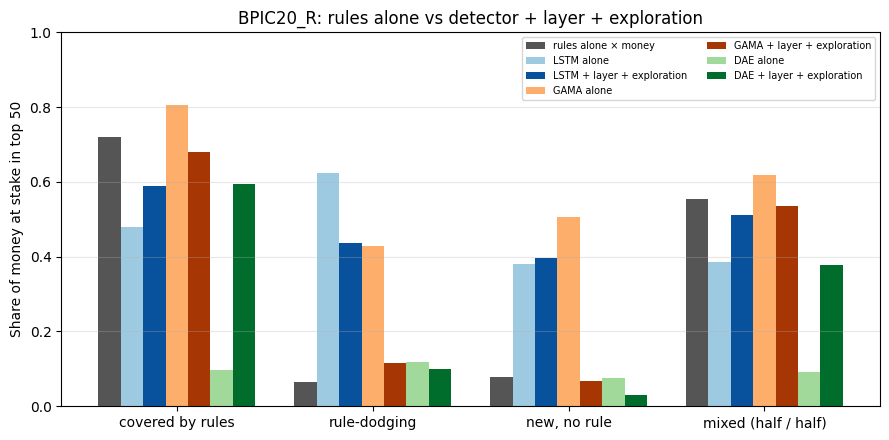

In [ ]:
# D.1 Scenarios: where do the rules stop working, and does the combination hold up?
SYS7 = (["rules alone × money", "rules alone (equal weights) × money", "amount alone"]
        + [f"{d} {s}" for d in DETECTORS for s in ["alone", "+ layer", "+ layer + exploration", "+ layer (equal weights)",
                                                     "+ layer + exploration (all types labelled)"]])
MR = f"MoneyRecall@{K}"
head = R7.pivot_table(index="system", columns="scenario", values=MR, aggfunc="mean").reindex(index=SYS7, columns=SCENARIOS)
print(f"{LOG_NAME} · TEST · {MR} (share of money at stake in the top {K}) · decoys {RATIO_V7}:1 · mean over seeds {SEEDS}")
print(head.round(3).to_string()); head.round(4).to_csv(f"{V7_DIR}/headline_money_recall.csv")
for metric in [f"costly_recall@{K}", f"LossRecall@{K}", f"decoys_in_top{K}"]:
    t_ = R7.pivot_table(index="system", columns="scenario", values=metric, aggfunc="mean").reindex(index=SYS7, columns=SCENARIOS)
    print(f"\n{metric}:"); print(t_.round(3).to_string())
    t_.round(4).to_csv(f"{V7_DIR}/headline_{metric.replace('@', 'at')}.csv")
print(f"\nNumber of costly cases per test pool (mean over seeds):",
      R7[R7.system == "amount alone"].groupby("scenario")["n_costly"].mean().reindex(SCENARIOS).round(1).to_dict())

fig, ax = plt.subplots(figsize=(9, 4.5))
show = ["rules alone × money"] + [f"{d} {s}" for d in DETECTORS for s in ["alone", "+ layer + exploration"]]
w = 0.8 / len(show); x = np.arange(len(SCENARIOS))
cols_ = ["#555555", "#9ecae1", "#08519c", "#fdae6b", "#a63603", "#a1d99b", "#006d2c"]
for i, (sname, c) in enumerate(zip(show, cols_)):
    ax.bar(x + (i - len(show) / 2 + 0.5) * w, head.loc[sname].values, w, label=sname, color=c)
ax.set_xticks(x); ax.set_xticklabels(["covered by rules", "rule-dodging", "new, no rule", "mixed (half / half)"])
ax.set_ylabel(f"Share of money at stake in top {K}"); ax.set_ylim(0, 1); ax.grid(axis="y", alpha=.3)
ax.set_title(f"{LOG_NAME}: rules alone vs detector + layer + exploration"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(f"{V7_DIR}/scenarios.png", dpi=150); plt.show()


In [ ]:
# D.2 Paired comparisons per scenario (Δ money at stake in the top K, 95% bootstrap) and Wilcoxon over detector × seed
WX7 = []
for (scen, comp), g_ in D7.groupby(["scenario", "comparison"]):
    x = g_["delta_EUR_money_topK"].values
    WX7.append({"scenario": scen, "comparison": comp, "pairs": len(x), "improved": int((x > 0).sum()),
                "significant_better": int((g_["significant"] & (x > 0)).sum()),
                "significant_worse": int((g_["significant"] & (x < 0)).sum()),
                "mean_delta_MoneyRecall": g_["delta_MoneyRecall"].mean(),
                "wilcoxon_p_one_sided": wilcoxon(x, alternative="greater").pvalue if (x != 0).any() and len(x) >= 5 else np.nan})
WX7 = pd.DataFrame(WX7)
print("Paired comparisons (Δ share of money at stake in the top K; p one-sided, 'better'):")
print(WX7.round(4).to_string(index=False)); WX7.to_csv(f"{V7_DIR}/wilcoxon_this_log.csv", index=False)


Paired comparisons (Δ share of money at stake in the top K; p one-sided, 'better'):
scenario                      comparison  pairs  improved  significant_better  significant_worse  mean_delta_MoneyRecall  wilcoxon_p_one_sided
 covered        hybrid vs detector alone      9         6                   4                  0                  0.1609                0.0645
 covered           hybrid vs rules alone      9         1                   0                  2                 -0.0984                0.9785
 covered            layer vs rules alone      9         1                   0                  1                 -0.0489                0.9727
 covered        learned vs equal weights      9         9                   5                  0                  0.1750                0.0020
 covered rules: learned vs equal weights      3         3                   1                  0                  0.3290                   NaN
   dodge        hybrid vs detector alone      9         1 


MoneyRecall@50 under rule damage: rules removed at random (count)
level                                     0.0    2.0    4.0    6.0    8.0    10.0
scenario family                                                                  
covered  detector + layer                0.671  0.622  0.618  0.532  0.438  0.448
         detector + layer + exploration  0.621  0.595  0.591  0.520  0.463  0.452
         rules alone × money             0.720  0.727  0.670  0.538  0.419  0.403
mixed    detector + layer                0.523  0.500  0.467  0.422  0.347  0.389
         detector + layer + exploration  0.475  0.461  0.454  0.424  0.367  0.414
         rules alone × money             0.555  0.516  0.499  0.425  0.347  0.416

MoneyRecall@50 under rule damage: thresholds × factor
level                                     0.50   0.75   1.00   1.50   2.00
scenario family                                                           
covered  detector + layer                0.561  0.594  0.671  0.645  0.7

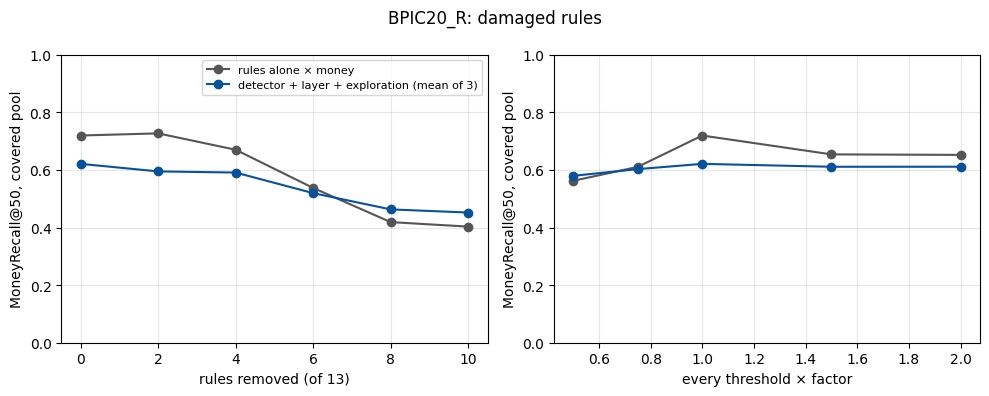


MoneyRecall lost from 0 to 10 rules removed (mean over draws):
          loss_rules_alone  loss_hybrid  rules_lose_more
scenario                                                
covered              0.316        0.169            0.778
mixed                0.139        0.061            0.667


In [ ]:
# D.3 Damaged rules: how fast does each system lose money as rules disappear or are mis-set?
for kind in ["dropout", "thresholds"]:
    sub = DM7[DM7.damage == kind].copy()
    sub["family"] = np.where(sub.system == "rules alone × money", "rules alone × money",
                             np.where(sub.system.str.endswith("exploration"), "detector + layer + exploration", "detector + layer"))
    t_ = sub.groupby(["scenario", "family", "level"])[MR].mean().unstack("level").round(3)
    print(f"\n{MR} under rule damage: {'rules removed at random (count)' if kind == 'dropout' else 'thresholds × factor'}")
    print(t_.to_string()); t_.to_csv(f"{V7_DIR}/damage_{kind}.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, kind in zip(axes, ["dropout", "thresholds"]):
    sub = DM7[(DM7.damage == kind) & (DM7.scenario == "covered")]
    for sname, c, lab in [("rules alone × money", "#555555", "rules alone × money"),
                          ("+ layer + exploration", "#08519c", "detector + layer + exploration (mean of 3)")]:
        s_ = sub[sub.system == sname] if sname.startswith("rules") else sub[sub.system.str.endswith(sname)]
        m_ = s_.groupby("level")[MR].mean()
        ax.plot(m_.index, m_.values, "o-", color=c, label=lab)
    ax.set_xlabel("rules removed (of 13)" if kind == "dropout" else "every threshold × factor")
    ax.set_ylabel(f"{MR}, covered pool"); ax.set_ylim(0, 1); ax.grid(alpha=.3)
axes[0].legend(fontsize=8); fig.suptitle(f"{LOG_NAME}: damaged rules"); plt.tight_layout()
plt.savefig(f"{V7_DIR}/rule_damage.png", dpi=150); plt.show()

# slope test: loss of money recall from 0 to the most damage, per seed, rules alone vs each hybrid
DS = []
for (seed, scen), g_ in DM7[DM7.damage == "dropout"].groupby(["seed", "scenario"]):
    m_ = g_.groupby(["system", "level"])[MR].mean().unstack("level")
    drop_r = m_.loc["rules alone × money", 0] - m_.loc["rules alone × money", max(DROP_KS)]
    for det in DETECTORS:
        h_ = f"{det} + layer + exploration"
        DS.append({"seed": seed, "scenario": scen, "detector": det, "loss_rules_alone": drop_r,
                   "loss_hybrid": m_.loc[h_, 0] - m_.loc[h_, max(DROP_KS)]})
DS = pd.DataFrame(DS); DS["rules_lose_more"] = DS["loss_rules_alone"] > DS["loss_hybrid"]
print(f"\nMoneyRecall lost from 0 to {max(DROP_KS)} rules removed (mean over draws):")
print(DS.groupby("scenario")[["loss_rules_alone", "loss_hybrid", "rules_lose_more"]].mean().round(3).to_string())
DS.to_csv(f"{V7_DIR}/damage_slopes.csv", index=False)


Rule reliability on validation (known types) and the learned weight (mean over detectors and seeds):
      fires_val  precision_val  false_alarm_rate  learned_weight
rule                                                            
F1        4.333          1.000             0.000           2.315
F2        0.000            NaN             0.000             NaN
F3       11.000          0.000             0.008          -0.618
F6        2.000          0.000             0.002          -0.031
F7        0.000            NaN             0.000             NaN
F8       72.333          0.046             0.052           0.162
F9       64.333          0.000             0.049          -0.669
F10       1.000          0.000             0.001          -0.039
F11       6.333          1.000             0.000           2.747
F12      52.333          0.167             0.033           2.321
F13     245.333          0.061             0.175           1.640
F14       6.333          0.836             0.001      

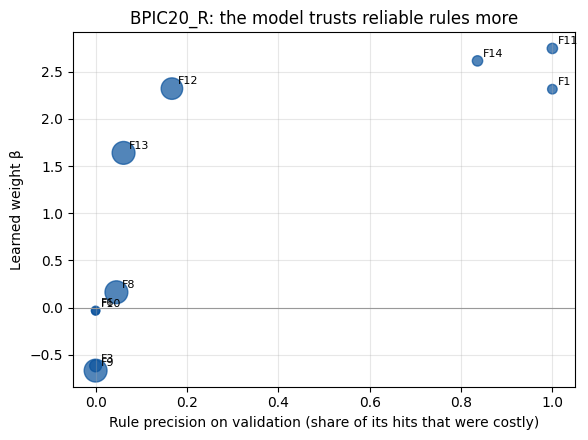

In [ ]:
# D.4 What the evidence model learns: weights vs how reliable each rule is
cw = C7[C7.feature.str.startswith("F")].groupby("feature")["beta"].mean()
rel = RS7.groupby("rule")[["fires_val", "precision_val", "false_alarm_rate"]].mean()
WT = rel.join(cw.rename("learned_weight"), how="left").reindex([r for r in RULES_V3 if r in rel.index])
zb = C7[C7.feature.str.startswith("z_")].groupby("detector")["beta"].mean().rename("weight per SD of z")
print("Rule reliability on validation (known types) and the learned weight (mean over detectors and seeds):")
print(WT.round(3).to_string()); WT.to_csv(f"{V7_DIR}/weights_vs_reliability.csv")
print("\nLearned weight of the detector's z (per standard deviation):"); print(zb.round(3).to_string())
_m = C7[C7.feature.str.startswith("F")].merge(RS7.rename(columns={"rule": "feature"}), on=["seed", "feature"])
_m = _m.dropna(subset=["precision_val"])
RHO = spearmanr(_m["beta"], _m["precision_val"]) if len(_m) > 3 else None
if RHO is not None:
    print(f"\nSpearman (learned weight, rule precision) over rule × detector × seed: rho = {RHO.correlation:.2f}, "
          f"p = {RHO.pvalue:.3g}, n = {len(_m)}")
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(WT["precision_val"], WT["learned_weight"], s=30 + 4 * WT["fires_val"].clip(upper=60), color="#08519c", alpha=.7)
for r, row in WT.dropna(subset=["precision_val", "learned_weight"]).iterrows():
    ax.annotate(r, (row["precision_val"], row["learned_weight"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.axhline(0, color="#999", lw=.8); ax.set_xlabel("Rule precision on validation (share of its hits that were costly)")
ax.set_ylabel("Learned weight β"); ax.set_title(f"{LOG_NAME}: the model trusts reliable rules more"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{V7_DIR}/weights_vs_precision.png", dpi=150); plt.show()


In [ ]:
# D.5 Verdicts for this log
def mr(sys_, scen, col=None):
    return R7[(R7.system == sys_) & (R7.scenario == scen)][col or MR].mean()
def hyb_mean(scen, suffix="+ layer + exploration", col=None):
    return np.mean([mr(f"{d} {suffix}", scen, col) for d in DETECTORS])
CR = f"costly_recall@{K}"
V = {"log": LOG_NAME,
     "H23 rules alone: covered → dodge / new": f"{mr('rules alone × money', 'covered'):.2f} → "
         f"{mr('rules alone × money', 'dodge'):.2f} / {mr('rules alone × money', 'new'):.2f}",
     "H24 hybrid vs rules alone (dodge, new, mixed)": " | ".join(
         f"{s}: {hyb_mean(s):.2f} vs {mr('rules alone × money', s):.2f}" for s in ["dodge", "new", "mixed"]),
     "H25 MoneyRecall lost, 0→max rules removed (covered): rules / hybrid":
         f"{DS[DS.scenario == 'covered'].loss_rules_alone.mean():.2f} / {DS[DS.scenario == 'covered'].loss_hybrid.mean():.2f}",
     "H26 learned vs equal (covered, mixed)": " | ".join(
         f"{s}: {hyb_mean(s, '+ layer'):.2f} vs {hyb_mean(s, '+ layer (equal weights)'):.2f}" for s in ["covered", "mixed"])
         + (f" | rho(weight, precision) = {RHO.correlation:.2f}" if RHO is not None else ""),
     "H23b share of costly CASES caught, rules alone: covered → dodge / new":
         f"{mr('rules alone × money', 'covered', CR):.2f} → {mr('rules alone × money', 'dodge', CR):.2f} / "
         f"{mr('rules alone × money', 'new', CR):.2f}",
     "H24b costly cases caught, hybrid vs rules alone (dodge, new, mixed)": " | ".join(
         f"{s}: {hyb_mean(s, col=CR):.2f} vs {mr('rules alone × money', s, CR):.2f}" for s in ["dodge", "new", "mixed"]),
     "H27 mixed: hybrid / rules alone / detector alone": f"{hyb_mean('mixed'):.2f} / {mr('rules alone × money', 'mixed'):.2f} / "
         f"{np.mean([mr(f'{d} alone', 'mixed') for d in DETECTORS]):.2f}",
     "once new types are labelled (hybrid, dodge / new)": f"{hyb_mean('dodge', '+ layer + exploration (all types labelled)'):.2f} / "
         f"{hyb_mean('new', '+ layer + exploration (all types labelled)'):.2f}"}
V = pd.DataFrame([V]).T; V.columns = ["result"]
print(V.to_string()); V.to_csv(f"{V7_DIR}/verdicts.csv")


                                                                                                                                            result
log                                                                                                                                       BPIC20_R
H23 rules alone: covered → dodge / new                                                                                          0.72 → 0.06 / 0.08
H24 hybrid vs rules alone (dodge, new, mixed)                                        dodge: 0.22 vs 0.06 | new: 0.17 vs 0.08 | mixed: 0.48 vs 0.56
H25 MoneyRecall lost, 0→max rules removed (covered): rules / hybrid                                                                    0.32 / 0.17
H26 learned vs equal (covered, mixed)                                  covered: 0.67 vs 0.50 | mixed: 0.52 vs 0.36 | rho(weight, precision) = 0.87
H23b share of costly CASES caught, rules alone: covered → dodge / new                                                 

In [ ]:
# D.6 EXPLORATORY (added after seeing the first results; not pre-registered):
# how many of the 50 review slots should go to the detector's own top cases?
# 0% = layer only, 20% = the pre-registered hybrid, 100% = detector alone.
EXPLORE_GRID = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]
EX = []
for seed in SEEDS:
    tidx = world_cases(seed)
    tidx = tidx[tidx["split"] == "test"].set_index(CASE_COL)
    for scen in SCENARIOS:
        d = tidx.loc[POOLS[(seed, scen)]].reset_index()
        for det in DETECTORS:
            lay = apply_layer(d, LAYERS[seed]["Lk"][det]); raw = d[f"raw_{det}"].values
            for fr in EXPLORE_GRID:
                s = hybrid(lay, raw, frac=fr)
                m = metrics_v7(d, s)
                EX.append({"seed": seed, "scenario": scen, "detector": det, "explore_share": fr,
                           MR: m[MR], f"costly_recall@{K}": m[f"costly_recall@{K}"]})
EX = pd.DataFrame(EX); EX.round(4).to_csv(f"{V7_DIR}/exploration_sweep.csv", index=False)
for metric in [MR, f"costly_recall@{K}"]:
    t_ = EX.groupby(["scenario", "explore_share"])[metric].mean().unstack("explore_share").reindex(SCENARIOS).round(3)
    print(f"\n{metric} by share of the {K} slots given to the detector (mean over detectors and seeds):")
    print(t_.to_string()); t_.to_csv(f"{V7_DIR}/exploration_sweep_{metric.replace('@', 'at')}.csv")
print("\nDONE for", LOG_NAME, "->", V7_DIR)



MoneyRecall@50 by share of the 50 slots given to the detector (mean over detectors and seeds):
explore_share    0.0    0.1    0.2    0.3    0.4    0.5    0.6    0.8    1.0
scenario                                                                    
covered        0.671  0.654  0.621  0.656  0.671  0.666  0.641  0.577  0.460
dodge          0.098  0.165  0.218  0.251  0.286  0.342  0.355  0.384  0.390
new            0.100  0.103  0.165  0.196  0.187  0.178  0.201  0.284  0.321
mixed          0.523  0.517  0.475  0.492  0.509  0.497  0.501  0.464  0.365

costly_recall@50 by share of the 50 slots given to the detector (mean over detectors and seeds):
explore_share    0.0    0.1    0.2    0.3    0.4    0.5    0.6    0.8    1.0
scenario                                                                    
covered        0.725  0.723  0.695  0.699  0.672  0.657  0.607  0.536  0.459
dodge          0.061  0.114  0.182  0.232  0.281  0.325  0.336  0.381  0.451
new            0.093  0.117  0.157  

## Part E · Across logs (run after this notebook has run for each log)


In [ ]:
# E.1 Combine every log that has been run
parts = {k: [] for k in ["scenario_metrics.csv", "scenario_deltas.csv", "rule_damage.csv", "learned_weights.csv",
                         "rule_reliability.csv", "rule_hits_by_type.csv", "damage_slopes.csv", "exploration_sweep.csv"]}
for lg in ["BPIC20_D", "BPIC20_I", "BPIC20_PR", "BPIC20_R"]:
    d_ = (BASE_ROOT if lg == "BPIC20_D" else f"{BASE_ROOT}/{lg}") + "/21_v7_stress"
    if not os.path.exists(f"{d_}/scenario_metrics.csv"):
        print(lg, "- not run yet"); continue
    for f_ in parts:
        if os.path.exists(f"{d_}/{f_}"):
            x = pd.read_csv(f"{d_}/{f_}"); x.insert(0, "log", lg); parts[f_].append(x)
if parts["scenario_metrics.csv"]:
    sd = f"{BASE_ROOT}/21_v7_summary"; os.makedirs(sd, exist_ok=True)
    A = {k: pd.concat(v, ignore_index=True) for k, v in parts.items() if v}
    for k, v in A.items():
        v.to_csv(f"{sd}/{k.replace('.csv', '_all_logs.csv')}", index=False)
    AR = A["scenario_metrics.csv"]
    for scen in SCENARIOS:
        pv = AR[AR.scenario == scen].pivot_table(index="system", columns="log", values=MR, aggfunc="mean").reindex(SYS7).round(3)
        print(f"\n{MR} · pool: {scen} (mean over seeds)"); print(pv.to_string())
        pv.to_csv(f"{sd}/money_recall_{scen}_by_log.csv")
    CR_ = f"costly_recall@{K}"
    pv = AR.pivot_table(index="system", columns="scenario", values=CR_, aggfunc="mean").reindex(index=SYS7, columns=SCENARIOS).round(3)
    print(f"\n{CR_} (share of costly CASES in the top {K}), mean over logs and seeds:"); print(pv.to_string())
    pv.to_csv(f"{sd}/costly_recall_by_scenario.csv")
    pv = AR.pivot_table(index="system", columns="scenario", values=MR, aggfunc="mean").reindex(index=SYS7, columns=SCENARIOS).round(3)
    print(f"\n{MR}, mean over logs and seeds:"); print(pv.to_string()); pv.to_csv(f"{sd}/money_recall_by_scenario.csv")
    AD = A["scenario_deltas.csv"]; W = []
    for (scen, comp), g_ in AD.groupby(["scenario", "comparison"]):
        x = g_["delta_EUR_money_topK"].values
        W.append({"scenario": scen, "comparison": comp, "pairs (detector×log×seed)": len(x), "improved": int((x > 0).sum()),
                  "significant_better": int((g_["significant"] & (x > 0)).sum()),
                  "significant_worse": int((g_["significant"] & (x < 0)).sum()),
                  "mean_delta_MoneyRecall": round(g_["delta_MoneyRecall"].mean(), 3),
                  "wilcoxon_p_one_sided": wilcoxon(x, alternative="greater").pvalue if (x != 0).any() and len(x) >= 5 else np.nan})
    W = pd.DataFrame(W); print("\nOverall paired tests:"); print(W.to_string(index=False))
    W.to_csv(f"{sd}/wilcoxon_all_logs.csv", index=False)
    DMa = A["rule_damage.csv"]
    DMa["family"] = np.where(DMa.system == "rules alone × money", "rules alone × money",
                             np.where(DMa.system.str.endswith("exploration"), "detector + layer + exploration", "detector + layer"))
    for kind in ["dropout", "thresholds"]:
        t_ = DMa[DMa.damage == kind].groupby(["scenario", "family", "level"])[MR].mean().unstack("level").round(3)
        print(f"\nRule damage ({kind}), all logs:"); print(t_.to_string()); t_.to_csv(f"{sd}/damage_{kind}_all_logs.csv")
    if "damage_slopes.csv" in A:
        x = A["damage_slopes.csv"]; x = x[x.scenario == "covered"]
        dd = (x["loss_rules_alone"] - x["loss_hybrid"]).values
        print(f"\nH25 (covered): rules alone lose more than the hybrid in {int((dd > 0).sum())}/{len(dd)} detector×log×seed; "
              f"Wilcoxon p = {wilcoxon(dd, alternative='greater').pvalue if (dd != 0).any() else np.nan:.3g}")
    m_ = A["learned_weights.csv"]; m_ = m_[m_.feature.str.startswith("F")].merge(
        A["rule_reliability.csv"].rename(columns={"rule": "feature"}), on=["log", "seed", "feature"]).dropna(subset=["precision_val"])
    if len(m_) > 3:
        rho = spearmanr(m_["beta"], m_["precision_val"])
        print(f"\nH26: Spearman (learned rule weight, rule precision), all logs: rho = {rho.correlation:.2f}, p = {rho.pvalue:.3g}, n = {len(m_)}")
    if "exploration_sweep.csv" in A:
        for metric in [MR, f"costly_recall@{K}"]:
            t_ = (A["exploration_sweep.csv"].groupby(["scenario", "explore_share"])[metric].mean()
                  .unstack("explore_share").reindex(SCENARIOS).round(3))
            print(f"\nEXPLORATORY · {metric} by share of slots given to the detector, all logs:"); print(t_.to_string())
            t_.to_csv(f"{sd}/exploration_sweep_{metric.replace('@', 'at')}_all_logs.csv")



MoneyRecall@50 · pool: covered (mean over seeds)
log                                              BPIC20_D  BPIC20_I  BPIC20_PR  BPIC20_R
system                                                                                  
rules alone × money                                 0.914     1.000      0.782     0.720
rules alone (equal weights) × money                 0.384     0.863      0.782     0.391
amount alone                                        0.232     0.642      0.766     0.220
LSTM alone                                          0.428     0.222      0.395     0.479
LSTM + layer                                        0.757     0.969      0.782     0.599
LSTM + layer + exploration                          0.676     0.953      0.778     0.589
LSTM + layer (equal weights)                        0.614     0.840      0.603     0.545
LSTM + layer + exploration (all types labelled)     0.740     0.947      0.988     0.583
GAMA alone                                          0.321   